# 🏠 House Price Prediction

## 2️⃣ Dataset Loading & Exploratory Data Analysis 

### 1.1 Import libraries and load dataset

In [22]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import os

# Load dataset
df = pd.read_csv("train.csv")

# Create output folders
os.makedirs("outputs", exist_ok=True)
os.makedirs("outputs/graphs", exist_ok=True)


# Display first 5 rows
df.head()

,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000


In [2]:
df.shape ## Shape Of Dataset

(1460, 81)

In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1460 entries, 0 to 1459
Data columns (total 81 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Id             1460 non-null   int64  
 1   MSSubClass     1460 non-null   int64  
 2   MSZoning       1460 non-null   object 
 3   LotFrontage    1201 non-null   float64
 4   LotArea        1460 non-null   int64  
 5   Street         1460 non-null   object 
 6   Alley          91 non-null     object 
 7   LotShape       1460 non-null   object 
 8   LandContour    1460 non-null   object 
 9   Utilities      1460 non-null   object 
 10  LotConfig      1460 non-null   object 
 11  LandSlope      1460 non-null   object 
 12  Neighborhood   1460 non-null   object 
 13  Condition1     1460 non-null   object 
 14  Condition2     1460 non-null   object 
 15  BldgType       1460 non-null   object 
 16  HouseStyle     1460 non-null   object 
 17  OverallQual    1460 non-null   int64  
 18  OverallC

#### Statistical summary

In [4]:
df.describe()

,Id,MSSubClass,LotFrontage,LotArea,OverallQual,OverallCond,YearBuilt,YearRemodAdd,MasVnrArea,BsmtFinSF1,...,WoodDeckSF,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,MiscVal,MoSold,YrSold,SalePrice
count,1460.000000,1460.000000,1201.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1452.000000,1460.000000,...,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000
mean,730.500000,56.897260,70.049958,10516.828082,6.099315,5.575342,1971.267808,1984.865753,103.685262,443.639726,...,94.244521,46.660274,21.954110,3.409589,15.060959,2.758904,43.489041,6.321918,2007.815753,180921.195890
std,421.610009,42.300571,24.284752,9981.264932,1.382997,1.112799,30.202904,20.645407,181.066207,456.098091,...,125.338794,66.256028,61.119149,29.317331,55.757415,40.177307,496.123024,2.703626,1.328095,79442.502883
min,1.000000,20.000000,21.000000,1300.000000,1.000000,1.000000,1872.000000,1950.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,2006.000000,34900.000000
25%,365.750000,20.000000,59.000000,7553.500000,5.000000,5.000000,1954.000000,1967.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,5.000000,2007.000000,129975.000000
50%,730.500000,50.000000,69.000000,9478.500000,6.000000,5.000000,1973.000000,1994.000000,0.000000,383.500000,...,0.000000,25.000000,0.000000,0.000000,0.000000,0.000000,0.000000,6.000000,2008.000000,163000.000000
75%,1095.250000,70.000000,80.000000,11601.500000,7.000000,6.000000,2000.000000,2004.000000,166.000000,712.250000,...,168.000000,68.000000,0.000000,0.000000,0.000000,0.000000,0.000000,8.000000,2009.000000,214000.000000
max,1460.000000,190.000000,313.000000,215245.000000,10.000000,9.000000,2010.000000,2010.000000,1600.000000,5644.000000,...,857.000000,547.000000,552.000000,508.000000,480.000000,738.000000,15500.000000,12.000000,2010.000000,755000.000000


### Numerical, categorical aur missing columns count karo

In [5]:
# Numerical columns
numerical_cols = df.select_dtypes(
    include="number"
).columns

# Categorical columns
categorical_cols = df.select_dtypes(
    include=["object", "category"]
).columns

# Columns with missing values
missing_cols = df.columns[df.isnull().any()]

print("Numerical Columns:", len(numerical_cols))
print("Categorical Columns:", len(categorical_cols))
print("Columns with Missing Values:", len(missing_cols))

Numerical Columns: 38
Categorical Columns: 43
Columns with Missing Values: 19


#### Missing values report

In [6]:
missing_values = df.isnull().sum()

missing_values = missing_values[
    missing_values > 0
].sort_values(ascending=False)

display(missing_values)

PoolQC          1453
MiscFeature     1406
Alley           1369
Fence           1179
MasVnrType       872
FireplaceQu      690
LotFrontage      259
GarageType        81
GarageYrBlt       81
GarageFinish      81
GarageQual        81
GarageCond        81
BsmtExposure      38
BsmtFinType2      38
BsmtQual          37
BsmtCond          37
BsmtFinType1      37
MasVnrArea         8
Electrical         1
dtype: int64

### SalePrice ka histogram aur Q-Q plot

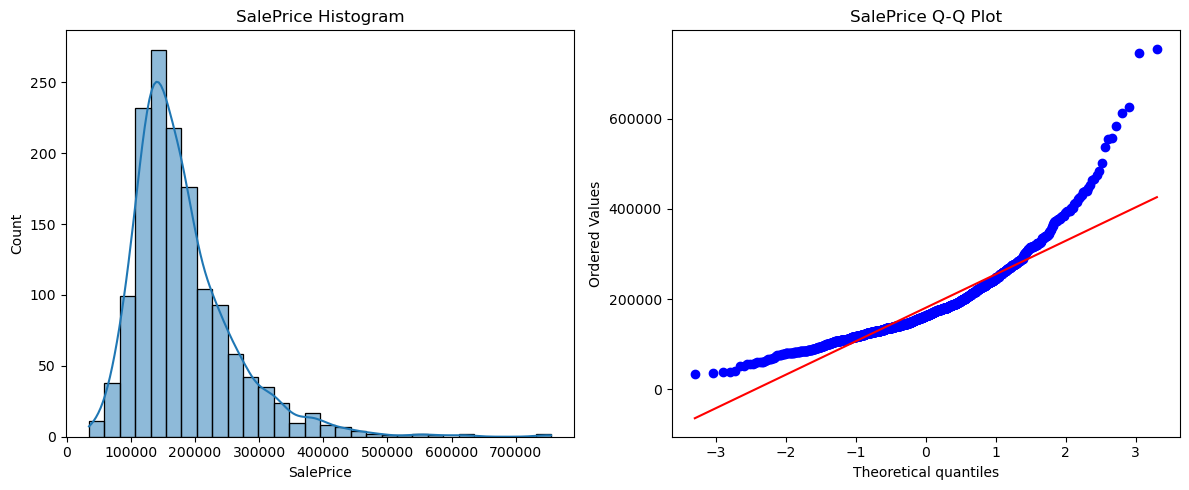

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Histogram
sns.histplot(
    df["SalePrice"],
    bins=30,
    kde=True,
    ax=axes[0]
)
axes[0].set_title("SalePrice Histogram")

# Q-Q Plot
stats.probplot(
    df["SalePrice"],
    dist="norm",
    plot=axes[1]
)
axes[1].set_title("SalePrice Q-Q Plot")

plt.tight_layout()
plt.show()

### Apply log1p transformation

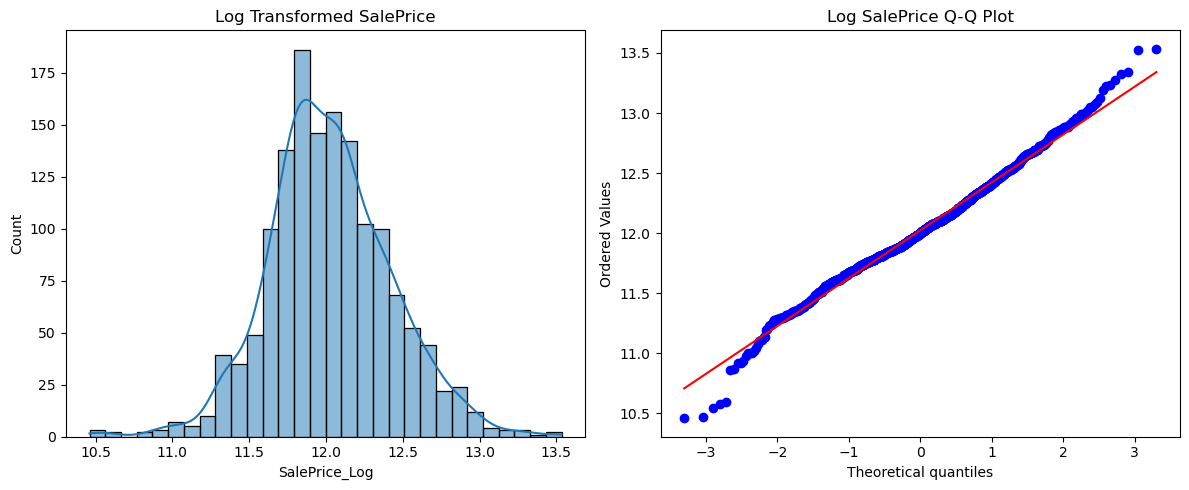

Original Skewness: 1.8828757597682129
Log Skewness: 0.12134661989685333


In [119]:
# Apply log1p transformation
df["SalePrice_Log"] = np.log1p(df["SalePrice"])

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Log transformed histogram
sns.histplot(
    df["SalePrice_Log"],
    bins=30,
    kde=True,
    ax=axes[0]
)
axes[0].set_title("Log Transformed SalePrice")

# Log transformed Q-Q plot
stats.probplot(
    df["SalePrice_Log"],
    dist="norm",
    plot=axes[1]
)
axes[1].set_title("Log SalePrice Q-Q Plot")

plt.tight_layout()
plt.savefig(
    "outputs/graphs/log SalePrice Q-Q plot.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Original Skewness:", df["SalePrice"].skew())
print("Log Skewness:", df["SalePrice_Log"].skew())

### Observation

The SalePrice distribution is right-skewed and is not perfectly normal. After applying log1p transformation, the distribution becomes less skewed. This transformation can help regression models learn the price patterns.

## 1.2 Univariate Analysis

### Numerical features ke histograms

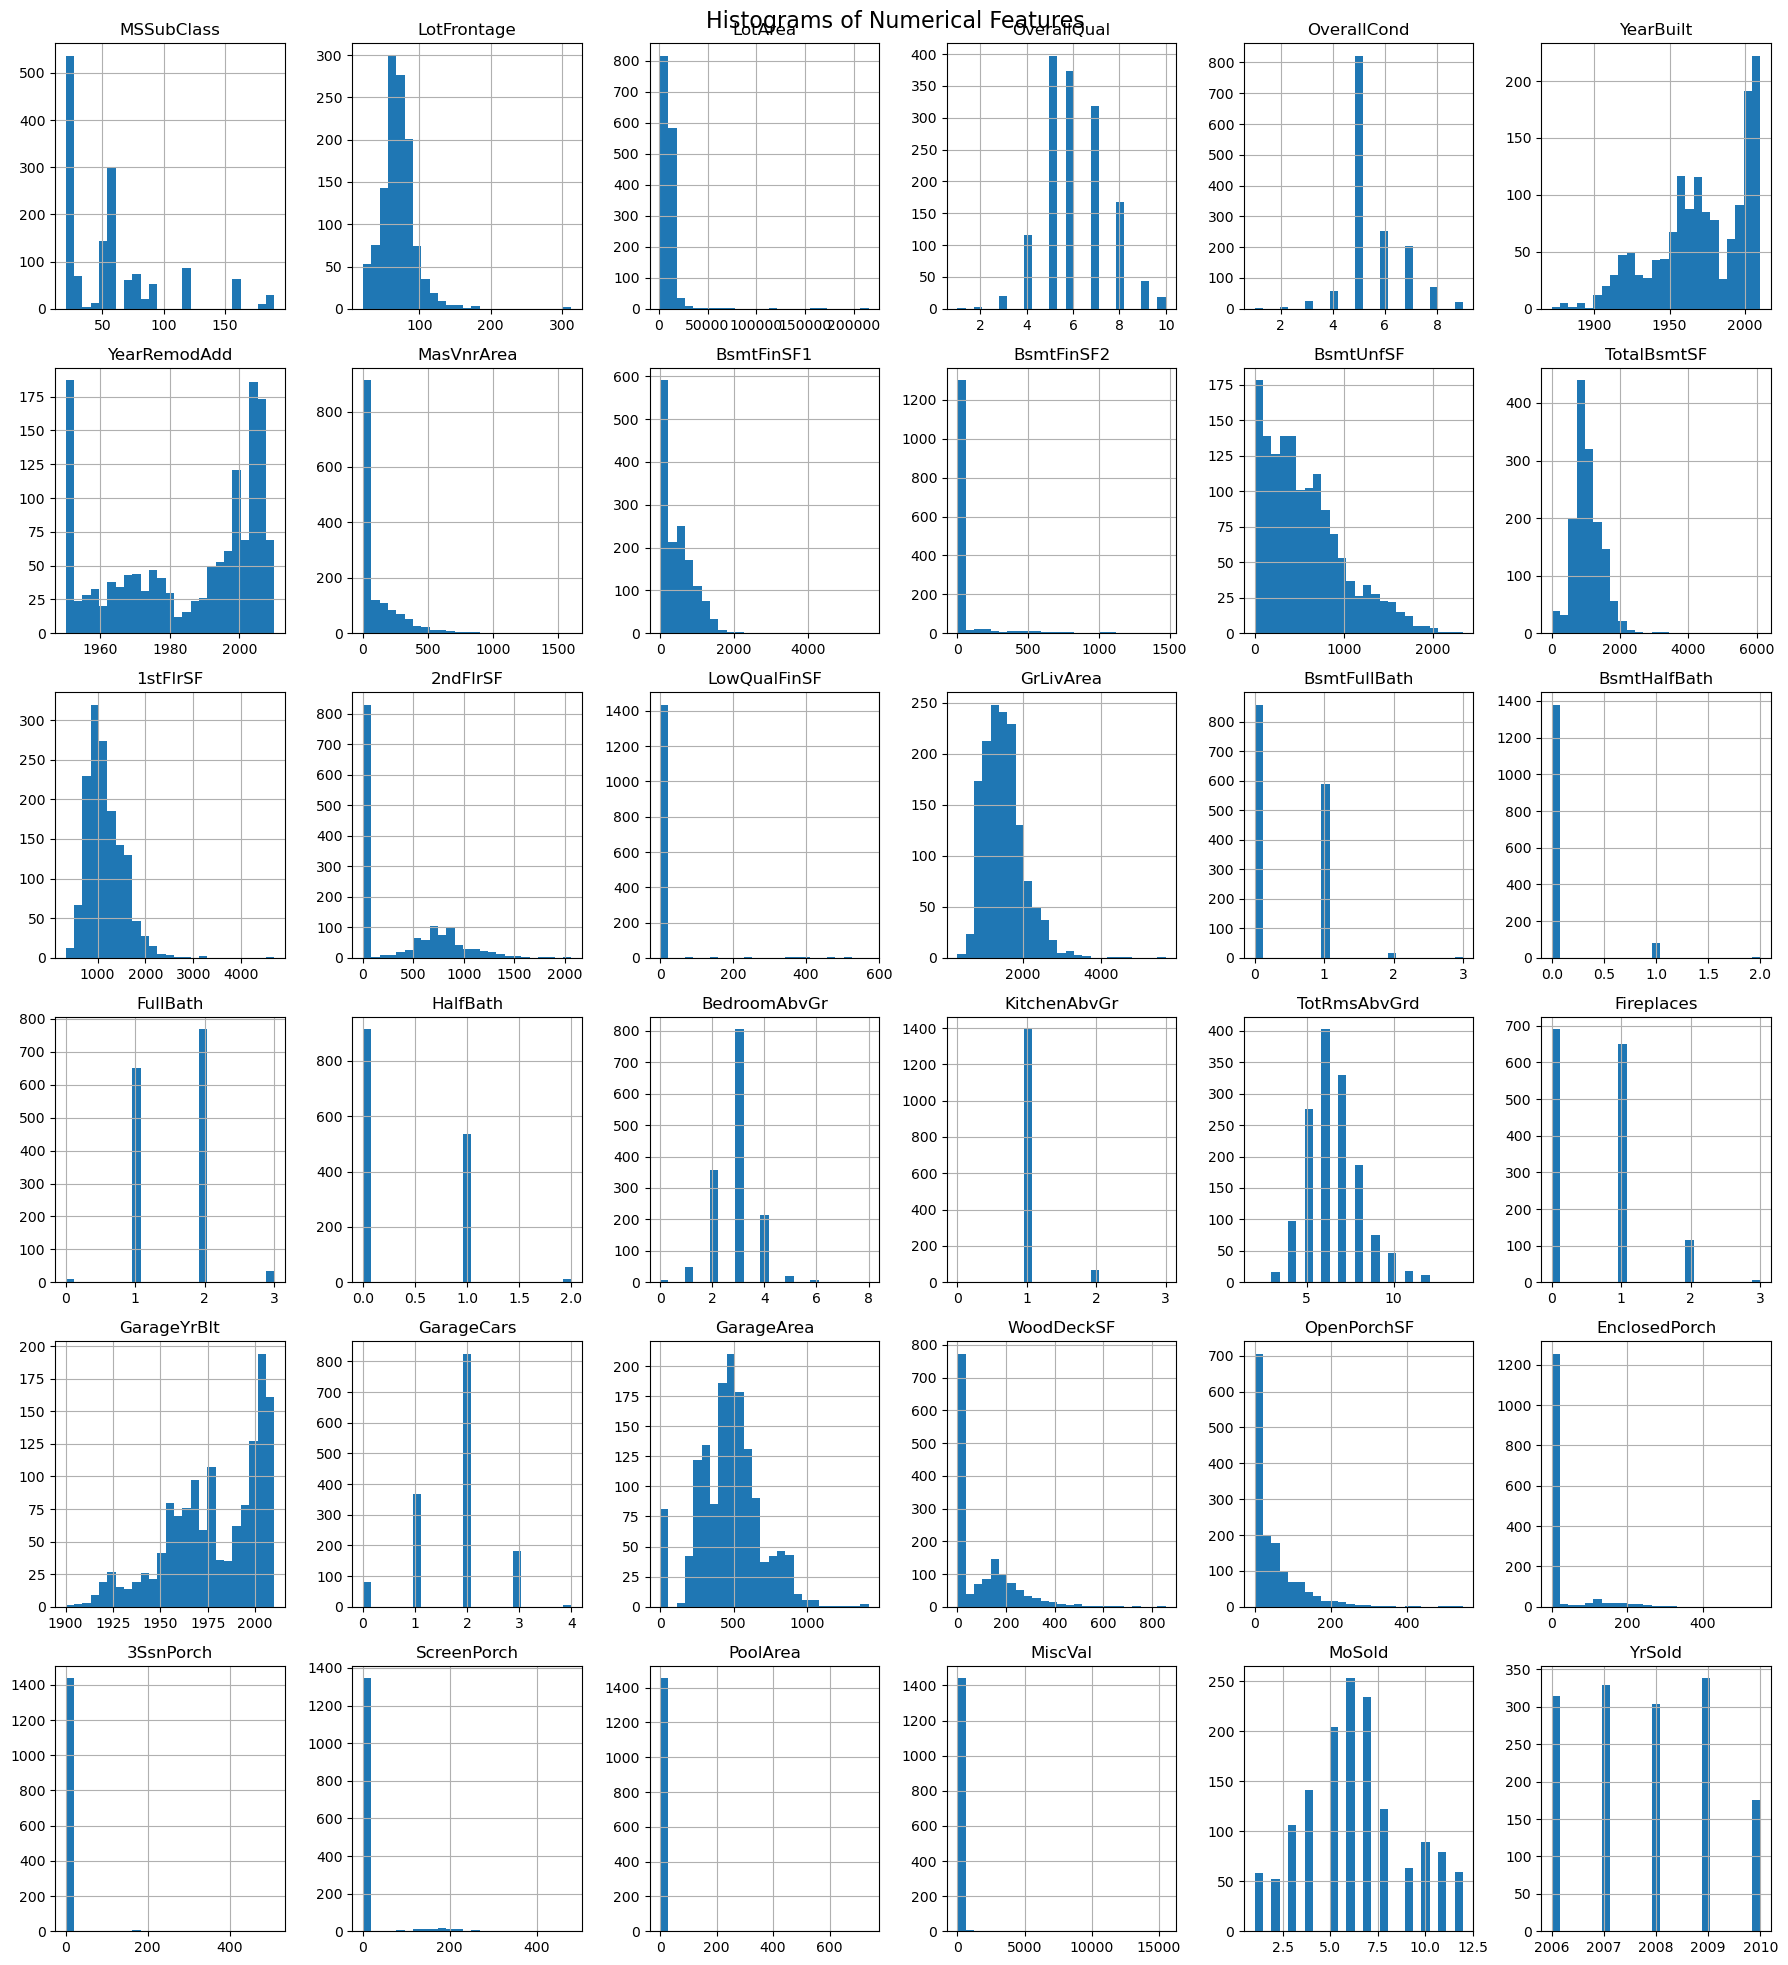

In [11]:
# Select numerical columns
numeric_data = df.select_dtypes(include="number")

# Remove ID and target columns
numeric_data = numeric_data.drop(
    columns=["Id", "SalePrice", "SalePrice_Log"],
    errors="ignore"
)

# Plot histograms
numeric_data.hist(
    figsize=(18, 20),
    bins=25
)

plt.suptitle(
    "Histograms of Numerical Features",
    fontsize=16
)

plt.tight_layout()
plt.show()

### Top 5 most skewed numerical columns

In [12]:
skew_values = numeric_data.skew().dropna()

# Select top 5 most skewed columns
top_5_skewed = (
    skew_values.abs()
    .sort_values(ascending=False)
    .head(5)
)

print("Top 5 Most Skewed Features:")
display(top_5_skewed.to_frame("Absolute Skewness"))

Top 5 Most Skewed Features:


,Absolute Skewness
MiscVal,24.476794
PoolArea,14.828374
LotArea,12.207688
3SsnPorch,10.304342
LowQualFinSF,9.011341


### Categorical columns ke countplots

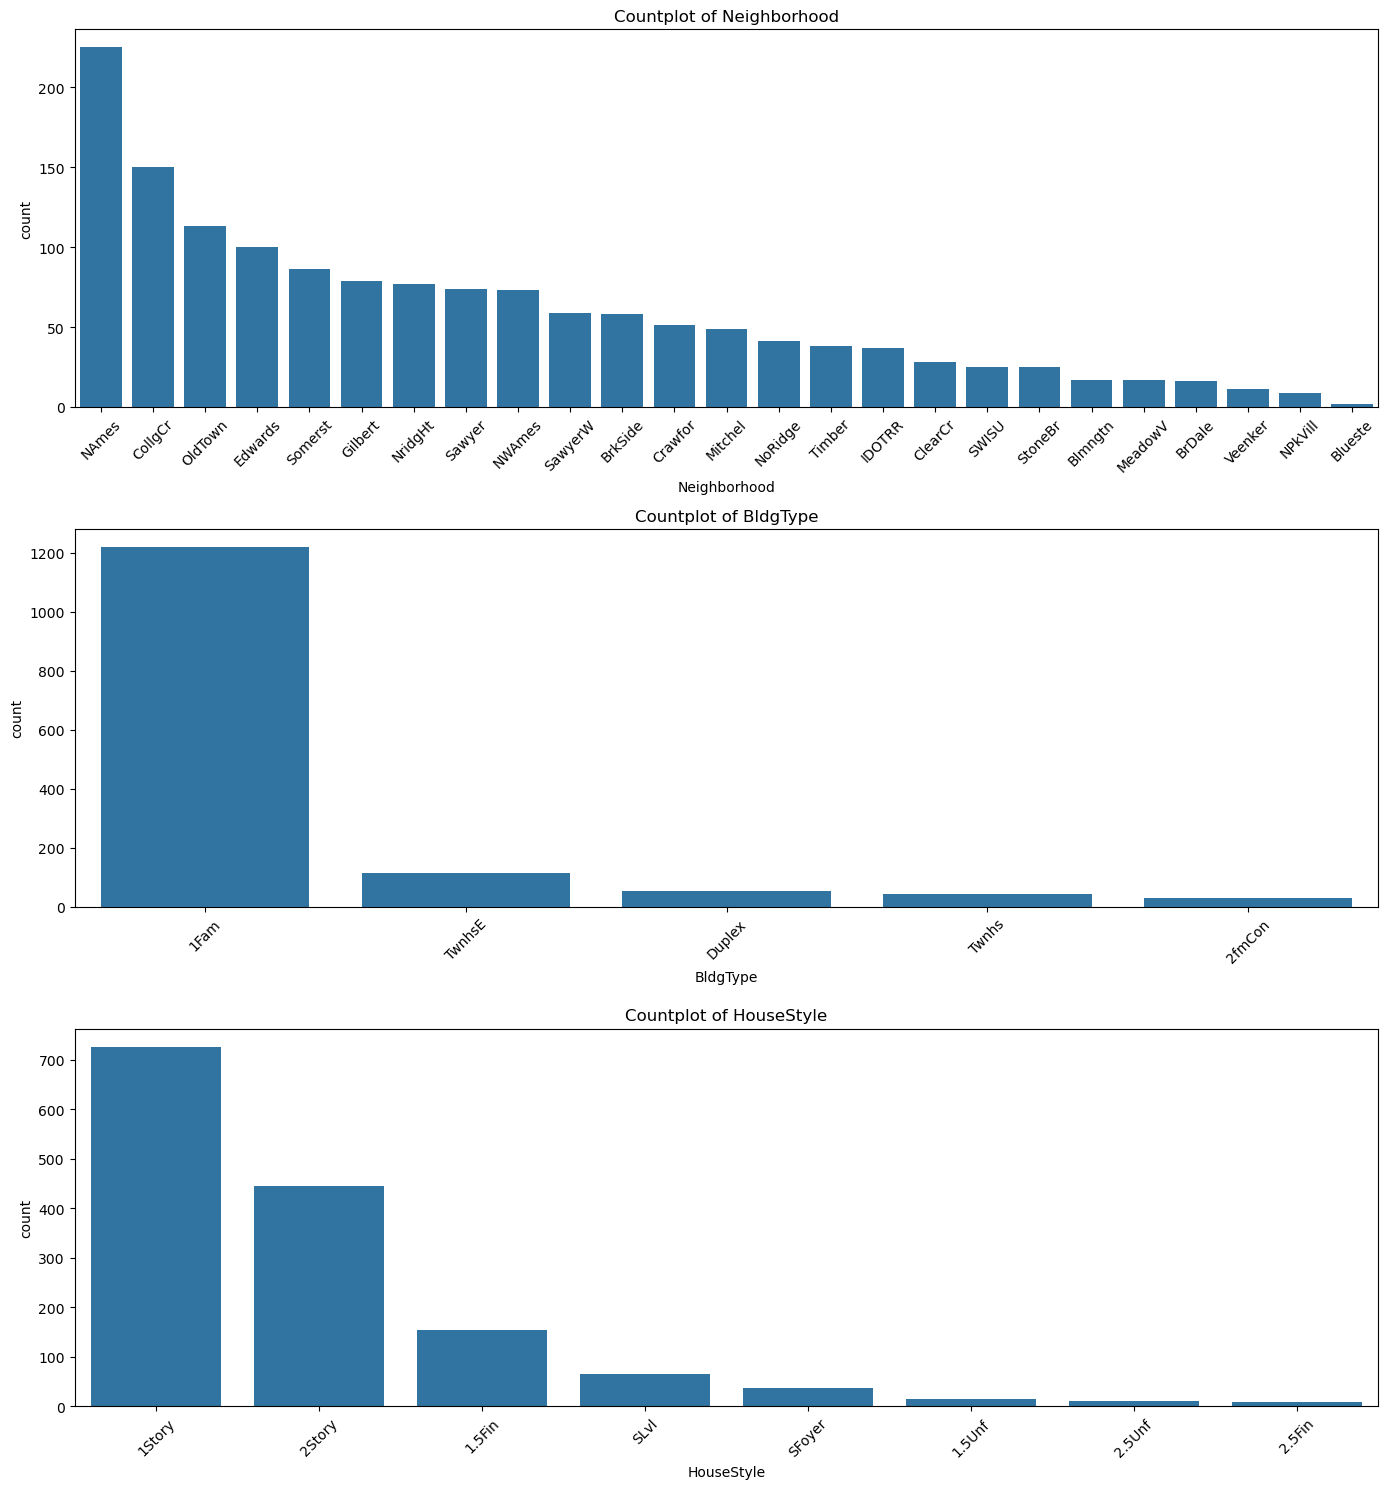

In [120]:
categorical_features = [
    "Neighborhood",
    "BldgType",
    "HouseStyle"
]

fig, axes = plt.subplots(3, 1, figsize=(14, 15))

for i, column in enumerate(categorical_features):
    sns.countplot(
        data=df,
        x=column,
        order=df[column].value_counts().index,
        ax=axes[i]
    )

    axes[i].set_title(f"Countplot of {column}")
    axes[i].tick_params(
        axis="x",
        rotation=45
    )

plt.tight_layout()
plt.savefig(
    "outputs/graphs/Count Plot.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

## 1.3 Bivariate Analysis

#### SalePrice ke saath top 15 correlated features ka heatmap

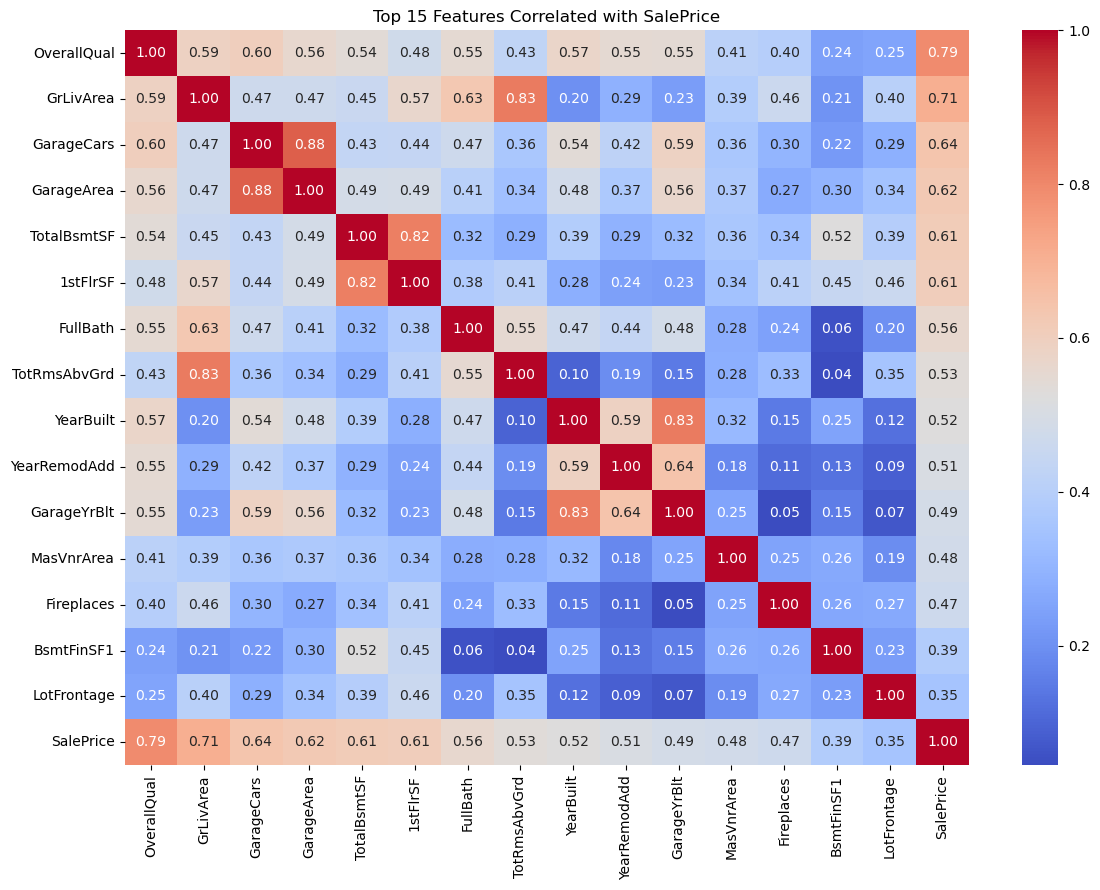

In [14]:
# Calculate correlation between numerical columns
correlation = df.select_dtypes(
    include="number"
).drop(
    columns=["Id", "SalePrice_Log"],
    errors="ignore"
).corr()

# Select top 15 features correlated with SalePrice
top_features = (
    correlation["SalePrice"]
    .drop("SalePrice")
    .abs()
    .sort_values(ascending=False)
    .head(15)
    .index.tolist()
)

# Include SalePrice in the heatmap
top_features.append("SalePrice")

plt.figure(figsize=(12, 9))

sns.heatmap(
    correlation.loc[top_features, top_features],
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Top 15 Features Correlated with SalePrice")
plt.tight_layout()
plt.show()

#### Scatterplot

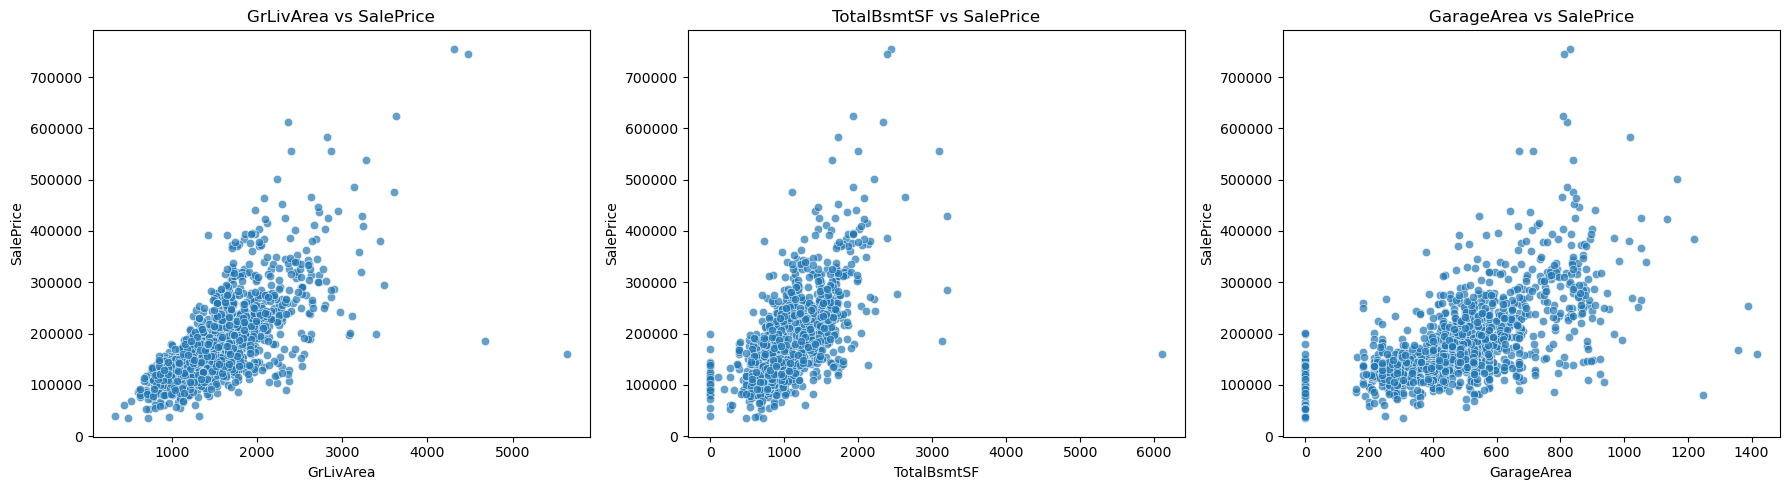

In [15]:
features = [
    "GrLivArea",
    "TotalBsmtSF",
    "GarageArea"
]

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for i, feature in enumerate(features):
    sns.scatterplot(
        data=df,
        x=feature,
        y="SalePrice",
        ax=axes[i],
        alpha=0.7
    )

    axes[i].set_title(f"{feature} vs SalePrice")

plt.tight_layout()
plt.show()

### OverallQual vs SalePrice boxplot

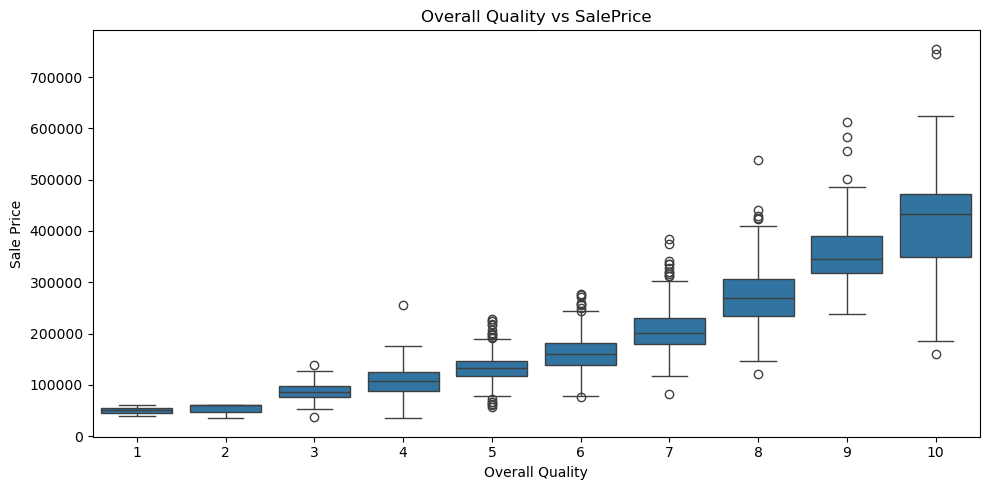

In [16]:
plt.figure(figsize=(10, 5))

sns.boxplot(
    data=df,
    x="OverallQual",
    y="SalePrice"
)

plt.title("Overall Quality vs SalePrice")
plt.xlabel("Overall Quality")
plt.ylabel("Sale Price")

plt.tight_layout()
plt.show()

### Neighborhood vs SalePrice boxplot

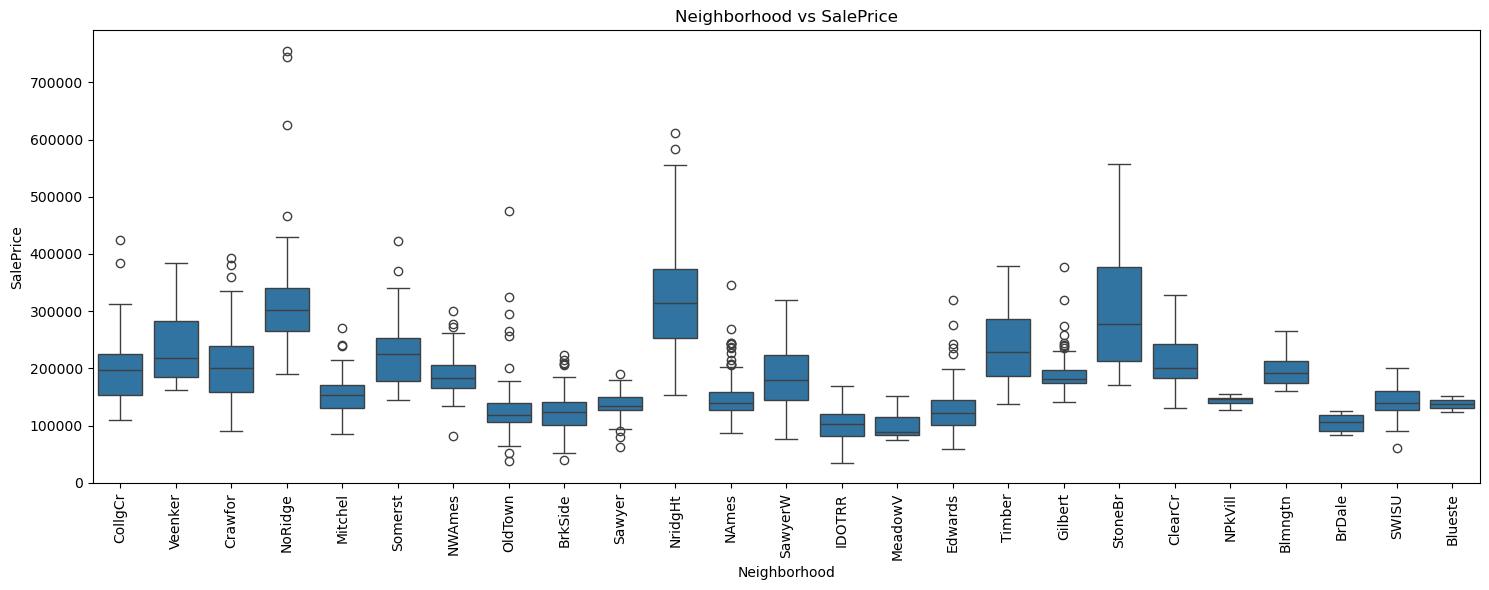

In [17]:
plt.figure(figsize=(15, 6))

sns.boxplot(
    data=df,
    x="Neighborhood",
    y="SalePrice"
)

plt.title("Neighborhood vs SalePrice")
plt.xticks(rotation=90)

plt.tight_layout()
plt.show()

#### Sabse expensive neighborhood identify 

In [18]:
neighborhood_prices = (
    df.groupby("Neighborhood")["SalePrice"]
    .median()
    .sort_values(ascending=False)
)

print("Top 5 Neighborhoods by Median Sale Price:")
display(neighborhood_prices.head(5))

print(
    "\nPriciest Neighborhood by Median Price:",
    neighborhood_prices.index[0]
)

Top 5 Neighborhoods by Median Sale Price:


Neighborhood
NridgHt    315000.0
NoRidge    301500.0
StoneBr    278000.0
Timber     228475.0
Somerst    225500.0
Name: SalePrice, dtype: float64


Priciest Neighborhood by Median Price: NridgHt


### Outliers identify aur flag

In [19]:
# Identify the two specified outliers
outlier_condition = (
    (df["GrLivArea"] > 4000) &
    (df["SalePrice"] < 300000)
)

outliers = df.loc[
    outlier_condition,
    ["Id", "GrLivArea", "SalePrice"]
]

print("Identified Outliers:")
display(outliers)

print("Number of Outliers:", len(outliers))

Identified Outliers:


,Id,GrLivArea,SalePrice
523,524,4676,184750
1298,1299,5642,160000


Number of Outliers: 2


# 3️⃣ Data Preprocessing & Feature Engineering

### 3.1  Handle Missing Values 

### Report missing values and percentages

In [23]:
missing_report = pd.DataFrame({
    "Missing Count": df.isnull().sum(),
    "Missing Percentage": df.isnull().mean() * 100
})

# Keep only columns with missing values
missing_report = missing_report[
    missing_report["Missing Count"] > 0
].sort_values(
    "Missing Percentage",
    ascending=False
)

display(missing_report.round(2))

# Save the report
missing_report.to_csv(
    "outputs/missing_values_report.csv"
)

print("Missing-value report saved in outputs folder.")

,Missing Count,Missing Percentage
PoolQC,1453,99.52
MiscFeature,1406,96.30
Alley,1369,93.77
Fence,1179,80.75
MasVnrType,872,59.73
FireplaceQu,690,47.26
LotFrontage,259,17.74
GarageType,81,5.55
GarageYrBlt,81,5.55
GarageFinish,81,5.55


Missing-value report saved in outputs folder.


### Create and save missing-values graph

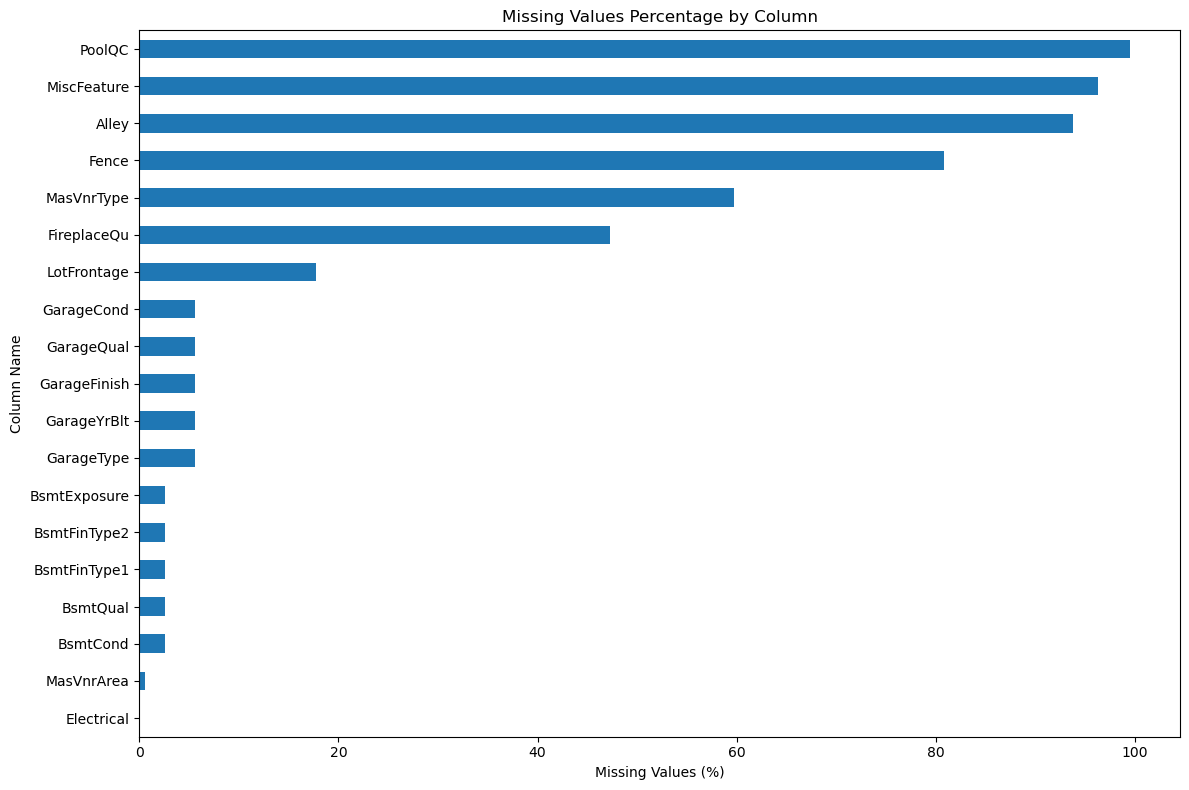

In [24]:
plt.figure(figsize=(12, 8))

missing_report["Missing Percentage"].sort_values().plot(
    kind="barh"
)

plt.title("Missing Values Percentage by Column")
plt.xlabel("Missing Values (%)")
plt.ylabel("Column Name")
plt.tight_layout()

plt.savefig(
    "outputs/graphs/missing_values_percentage.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

### Drop columns with more than 80% missing values

In [25]:
# Calculate missing percentage
missing_percent = df.isnull().mean() * 100

# Find columns with more than 80% missing values
columns_to_drop = missing_percent[
    missing_percent > 80
].index.tolist()

print("Columns to drop:", columns_to_drop)

# Drop those columns
df = df.drop(columns=columns_to_drop)

print("New dataset shape:", df.shape)

Columns to drop: ['Alley', 'PoolQC', 'Fence', 'MiscFeature']
New dataset shape: (1460, 77)


### Fill categorical missing values with "None"

In [26]:
# Categorical columns where missing means the feature is absent
none_columns = [
    "PoolQC",
    "Fence",
    "GarageType",
    "GarageFinish",
    "GarageQual",
    "GarageCond",
    "Alley",
    "MiscFeature",
    "FireplaceQu",
    "BsmtQual",
    "BsmtCond",
    "BsmtExposure",
    "BsmtFinType1",
    "BsmtFinType2",
    "MasVnrType"
]

for col in none_columns:
    if col in df.columns:
        df[col] = df[col].fillna("None")

print("Categorical missing values handled.")

Categorical missing values handled.


### Fill numerical missing values with zero

In [27]:
# Numerical columns where missing means the feature is absent
zero_columns = [
    "GarageArea",
    "GarageCars",
    "GarageYrBlt",
    "BsmtFinSF1",
    "BsmtFinSF2",
    "BsmtUnfSF",
    "TotalBsmtSF",
    "BsmtFullBath",
    "BsmtHalfBath",
    "MasVnrArea"
]

for col in zero_columns:
    if col in df.columns:
        df[col] = df[col].fillna(0)

print("Numerical absence values handled.")

Numerical absence values handled.


Interpretation: Agar basement ya garage nahi hai, toh usse related area ya capacity zero ho sakti hai. Ye rule sirf un features par apply karna chahiye jahan missing value ka meaning genuinely absence ho

### Fill remaining missing values

In [28]:
# Fill remaining numerical columns with median
numerical_columns = df.select_dtypes(
    include="number"
).columns

for col in numerical_columns:
    if df[col].isnull().any():
        df[col] = df[col].fillna(df[col].median())

# Fill remaining categorical columns with most frequent value
categorical_columns = df.select_dtypes(
    include=["object", "category"]
).columns

for col in categorical_columns:
    if df[col].isnull().any():
        mode_value = df[col].mode()

        if not mode_value.empty:
            df[col] = df[col].fillna(mode_value[0])

print("Remaining missing values handled.")

Remaining missing values handled.


In [30]:
remaining_missing = df.isnull().sum()

remaining_missing = remaining_missing[
    remaining_missing > 0
]

if remaining_missing.empty:
    print("No missing values remain.")
else:
    display(remaining_missing)

print("Final dataset shape:", df.shape)

No missing values remain.
Final dataset shape: (1460, 77)


### save The Cleanest data set

In [32]:
# Save cleaned dataset
df.to_csv(
    "outputs/cleaned_house_data.csv",
    index=False
)

### Graph after handling missing values

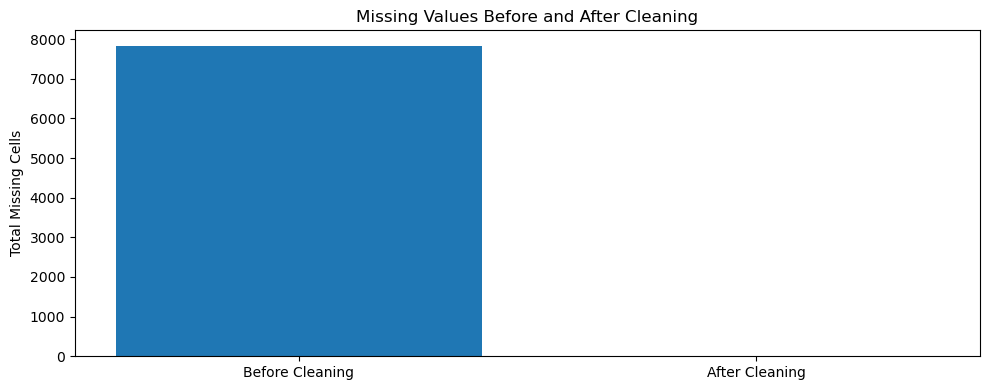

Cleaned dataset and graphs saved successfully.


In [31]:
plt.figure(figsize=(10, 4))

plt.bar(
    ["Before Cleaning", "After Cleaning"],
    [
        int(missing_report["Missing Count"].sum()),
        int(df.isnull().sum().sum())
    ]
)

plt.title("Missing Values Before and After Cleaning")
plt.ylabel("Total Missing Cells")
plt.tight_layout()

plt.savefig(
    "outputs/graphs/missing_values_before_after.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Cleaned dataset and graphs saved successfully.")

### Step 3.1: Missing Values Interpretation

The dataset contained missing values in several columns. First, I checked the missing-value count and percentage. I dropped columns with more than 80% missing values. I filled categorical values representing absent features with "None" and numerical values representing absent features with zero. I used the median for remaining numerical missing values and the most frequent value for remaining categorical missing values.

Finally, I checked the dataset again and saved the cleaned data and graphs in the outputs folder.

## 3.2: Outlier Removal

#### Find the Outlier

In [33]:
# Find houses with very large living area but low sale price
outlier_condition = (
    (df["GrLivArea"] > 4000) &
    (df["SalePrice"] < 300000)
)

outliers = df.loc[
    outlier_condition,
    ["Id", "GrLivArea", "SalePrice"]
]

print("Outlier rows found:", len(outliers))
display(outliers)

Outlier rows found: 2


,Id,GrLivArea,SalePrice
523,524,4676,184750
1298,1299,5642,160000


#### Plot the outliers

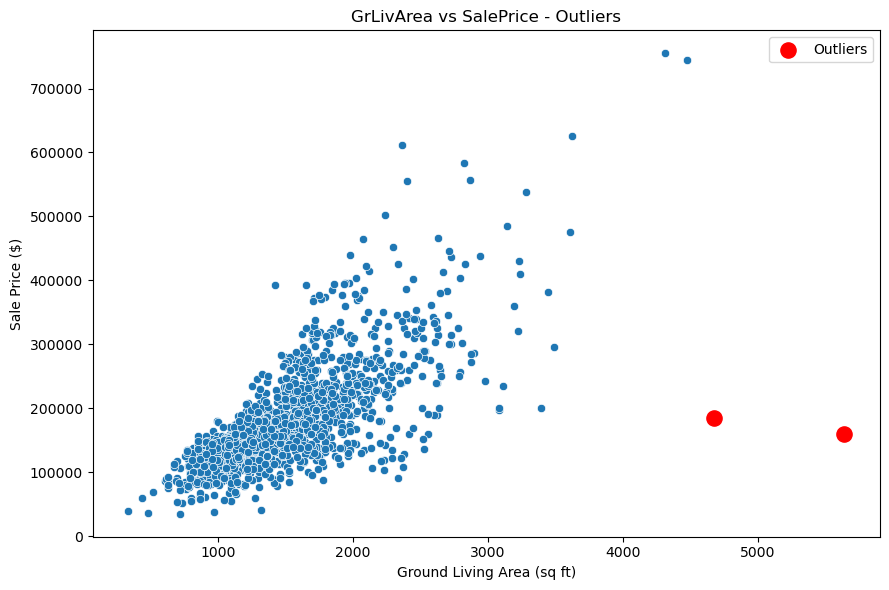

In [34]:

os.makedirs("outputs/graphs", exist_ok=True)

plt.figure(figsize=(9, 6))

sns.scatterplot(
    data=df,
    x="GrLivArea",
    y="SalePrice"
)

plt.scatter(
    outliers["GrLivArea"],
    outliers["SalePrice"],
    color="red",
    s=120,
    label="Outliers"
)

plt.title("GrLivArea vs SalePrice - Outliers")
plt.xlabel("Ground Living Area (sq ft)")
plt.ylabel("Sale Price ($)")
plt.legend()
plt.tight_layout()

plt.savefig(
    "outputs/graphs/outliers_before_removal.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

#### Remove the outlier rows

In [35]:
# Remove outlier rows
df_clean = df.loc[~outlier_condition].copy()

print("Rows before removal:", len(df))
print("Rows after removal:", len(df_clean))
print("Rows removed:", len(df) - len(df_clean))

Rows before removal: 1460
Rows after removal: 1458
Rows removed: 2


## save Dataset(cleaned)

In [36]:
df_clean.to_csv(
    "outputs/house_data_without_outliers.csv",
    index=False
)

print("Cleaned dataset saved successfully!")

Cleaned dataset saved successfully!


### Outlier Removal Interpretation

I identified two outlier rows where GrLivArea is greater than 4000 and SalePrice is below 300000. I removed these rows as instructed in the practical exam.

These houses have a very large living area but comparatively low sale prices. Keeping such extreme observations may pull the linear regression line away from the general data pattern and affect price predictions.

After removing the two rows, the dataset contains 1458 rows.

## 3.3: Feature Engineering

### Create new features

In [37]:
# Create total usable area
df_clean["TotalSF"] = (
    df_clean["TotalBsmtSF"].fillna(0)
    + df_clean["1stFlrSF"].fillna(0)
    + df_clean["2ndFlrSF"].fillna(0)
)

# Calculate house age at the time of sale
df_clean["HouseAge"] = (
    df_clean["YrSold"] - df_clean["YearBuilt"]
)

# Calculate years since the last remodeling
df_clean["RemodAge"] = (
    df_clean["YrSold"] - df_clean["YearRemodAdd"]
)

# Check whether the house has a garage
df_clean["HasGarage"] = (
    df_clean["GarageArea"].fillna(0) > 0
).astype(int)

# Check whether the house has a pool
df_clean["HasPool"] = (
    df_clean["PoolArea"].fillna(0) > 0
).astype(int)

print("New features created successfully!")

New features created successfully!


In [38]:
new_features = [
    "TotalSF",
    "HouseAge",
    "RemodAge",
    "HasGarage",
    "HasPool"
]

display(df_clean[new_features + ["SalePrice"]].head(10))

,TotalSF,HouseAge,RemodAge,HasGarage,HasPool,SalePrice
0,2566,5,5,1,0,208500
1,2524,31,31,1,0,181500
2,2706,7,6,1,0,223500
3,2473,91,36,1,0,140000
4,3343,8,8,1,0,250000
5,2158,16,14,1,0,143000
6,3380,3,2,1,0,307000
7,3197,36,36,1,0,200000
8,2726,77,58,1,0,129900
9,2068,69,58,1,0,118000


## graph of the new features

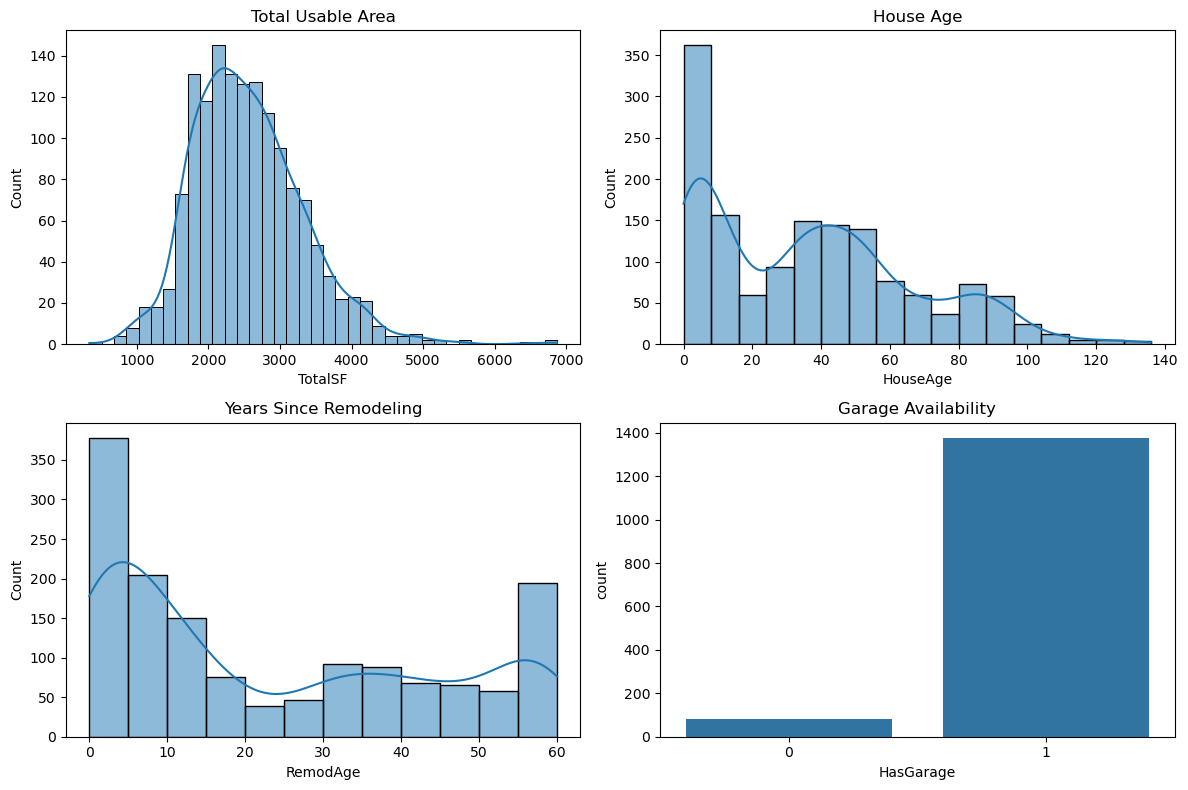

In [39]:
os.makedirs("outputs/graphs", exist_ok=True)

fig, axes = plt.subplots(2, 2, figsize=(12, 8))

sns.histplot(
    data=df_clean,
    x="TotalSF",
    kde=True,
    ax=axes[0, 0]
)
axes[0, 0].set_title("Total Usable Area")

sns.histplot(
    data=df_clean,
    x="HouseAge",
    kde=True,
    ax=axes[0, 1]
)
axes[0, 1].set_title("House Age")

sns.histplot(
    data=df_clean,
    x="RemodAge",
    kde=True,
    ax=axes[1, 0]
)
axes[1, 0].set_title("Years Since Remodeling")

sns.countplot(
    data=df_clean,
    x="HasGarage",
    ax=axes[1, 1]
)
axes[1, 1].set_title("Garage Availability")

plt.tight_layout()

plt.savefig(
    "outputs/graphs/feature_engineering.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [41]:
print("Garage Availability:")
display(df_clean["HasGarage"].value_counts())

print("\nPool Availability:")
display(df_clean["HasPool"].value_counts())

Garage Availability:


HasGarage
1    1377
0      81
Name: count, dtype: int64


Pool Availability:


HasPool
0    1452
1       6
Name: count, dtype: int64

### Feature Engineering Interpretation

I created five new features from the existing dataset.

- **TotalSF:** Represents the total basement and floor area of the house.
- **HouseAge:** Shows how old the house was when it was sold.
- **RemodAge:** Shows how many years had passed since the house was last remodelled.
- **HasGarage:** Returns 1 if the house has a garage and 0 otherwise.
- **HasPool:** Returns 1 if the house has a pool and 0 otherwise.

These new features provide useful information about house size, age and facilities, which may help the model predict house prices.

### 3.4 — Encoding & Scaling

In [42]:
from sklearn.preprocessing import (
    OneHotEncoder,
    StandardScaler,
    FunctionTransformer
)
from sklearn.impute import SimpleImputer

### Separate features and target

In [43]:
X = df_clean.drop(columns=["SalePrice", "Id"], errors="ignore").copy()
y = np.log1p(df_clean["SalePrice"])

print("Features shape:", X.shape)
print("Target shape:", y.shape)

Features shape: (1458, 80)
Target shape: (1458,)


### Ordinal Encoding

In [44]:
quality_columns = [
    "ExterQual",
    "KitchenQual",
    "BsmtQual",
    "FireplaceQu"
]

quality_mapping = {
    "None": 0,
    "Po": 1,
    "Fa": 2,
    "TA": 3,
    "Gd": 4,
    "Ex": 5
}

for col in quality_columns:
    if col in X.columns:
        X[col] = X[col].fillna("None").map(quality_mapping)

print(X[quality_columns].head())

   ExterQual  KitchenQual  BsmtQual  FireplaceQu
0          4            4         4            0
1          3            3         4            3
2          4            4         4            3
3          3            4         3            4
4          4            4         4            3


### Identify categorical and numerical columns

In [45]:
# Find categorical columns
categorical_columns = X.select_dtypes(
    include=["object", "category"]
).columns.tolist()

print("Categorical columns:", categorical_columns)
print("Total categorical columns:", len(categorical_columns))

# Check unique values in each categorical column
for col in categorical_columns:
    print(col, ":", X[col].nunique())

Categorical columns: ['MSZoning', 'Street', 'LotShape', 'LandContour', 'Utilities', 'LotConfig', 'LandSlope', 'Neighborhood', 'Condition1', 'Condition2', 'BldgType', 'HouseStyle', 'RoofStyle', 'RoofMatl', 'Exterior1st', 'Exterior2nd', 'MasVnrType', 'ExterCond', 'Foundation', 'BsmtCond', 'BsmtExposure', 'BsmtFinType1', 'BsmtFinType2', 'Heating', 'HeatingQC', 'CentralAir', 'Electrical', 'Functional', 'GarageType', 'GarageFinish', 'GarageQual', 'GarageCond', 'PavedDrive', 'SaleType', 'SaleCondition']
Total categorical columns: 35
MSZoning : 5
Street : 2
LotShape : 4
LandContour : 4
Utilities : 2
LotConfig : 5
LandSlope : 3
Neighborhood : 25
Condition1 : 9
Condition2 : 8
BldgType : 5
HouseStyle : 8
RoofStyle : 6
RoofMatl : 7
Exterior1st : 15
Exterior2nd : 16
MasVnrType : 4
ExterCond : 5
Foundation : 6
BsmtCond : 5
BsmtExposure : 5
BsmtFinType1 : 7
BsmtFinType2 : 7
Heating : 6
HeatingQC : 5
CentralAir : 2
Electrical : 5
Functional : 7
GarageType : 7
GarageFinish : 4
GarageQual : 6
GarageCon

### Label encode

In [46]:
if "Neighborhood" in X.columns:
    X["Neighborhood"] = (
        X["Neighborhood"]
        .fillna("Unknown")
        .astype("category")
        .cat.codes
    )

print(X[["Neighborhood"]].head())

   Neighborhood
0             5
1            24
2             5
3             6
4            15


### Identify skewed numerical features

In [47]:
ordinal_columns = [
    col for col in quality_columns if col in X.columns
]

binary_columns = [
    col for col in ["HasGarage", "HasPool"]
    if col in X.columns
]

numeric_columns = X.select_dtypes(
    include=np.number
).columns.tolist()

skewness = X[numeric_columns].skew()

skewed_columns = [
    col for col in numeric_columns
    if skewness[col] > 0.75
    and col not in ordinal_columns
    and col not in binary_columns
]

print("Skewed numerical columns:")
print(skewed_columns)

print("\nNumber of skewed columns:", len(skewed_columns))

Skewed numerical columns:
['MSSubClass', 'LotFrontage', 'LotArea', 'MasVnrArea', 'BsmtFinSF1', 'BsmtFinSF2', 'BsmtUnfSF', '1stFlrSF', '2ndFlrSF', 'LowQualFinSF', 'GrLivArea', 'BsmtHalfBath', 'KitchenAbvGr', 'WoodDeckSF', 'OpenPorchSF', 'EnclosedPorch', '3SsnPorch', 'ScreenPorch', 'PoolArea', 'MiscVal', 'TotalSF']

Number of skewed columns: 21


#### Apply log1p to skewed columns

In [48]:
for col in skewed_columns:
    # log1p requires values greater than or equal to -1
    if (X[col].dropna() >= 0).all():
        X[col] = np.log1p(X[col])

print("Log transformation completed.")
print(X[skewed_columns].head())

Log transformation completed.
   MSSubClass  LotFrontage   LotArea  MasVnrArea  BsmtFinSF1  BsmtFinSF2  \
0    4.110874     4.189655  9.042040    5.283204    6.561031         0.0   
1    3.044522     4.394449  9.169623    0.000000    6.886532         0.0   
2    4.110874     4.234107  9.328212    5.093750    6.188264         0.0   
3    4.262680     4.110874  9.164401    0.000000    5.379897         0.0   
4    4.110874     4.442651  9.565284    5.860786    6.486161         0.0   

   BsmtUnfSF  1stFlrSF  2ndFlrSF  LowQualFinSF  ...  BsmtHalfBath  \
0   5.017280  6.753438  6.751101           0.0  ...      0.000000   
1   5.652489  7.141245  0.000000           0.0  ...      0.693147   
2   6.075346  6.825460  6.765039           0.0  ...      0.000000   
3   6.293419  6.869014  6.629363           0.0  ...      0.000000   
4   6.196444  7.044033  6.960348           0.0  ...      0.000000   

   KitchenAbvGr  WoodDeckSF  OpenPorchSF  EnclosedPorch  3SsnPorch  \
0      0.693147    0.000000 

### Prepare One-Hot Encoding columns

In [49]:
categorical_columns = X.select_dtypes(
    include=["object", "category"]
).columns.tolist()

onehot_columns = [
    col for col in categorical_columns
    if X[col].nunique() <= 10
]

# Drop remaining high-cardinality categorical columns
high_cardinality_columns = [
    col for col in categorical_columns
    if col not in onehot_columns
]

print("One-Hot Encoding columns:")
print(onehot_columns)

print("\nHigh-cardinality columns to drop:")
print(high_cardinality_columns)

X = X.drop(columns=high_cardinality_columns)

One-Hot Encoding columns:
['MSZoning', 'Street', 'LotShape', 'LandContour', 'Utilities', 'LotConfig', 'LandSlope', 'Condition1', 'Condition2', 'BldgType', 'HouseStyle', 'RoofStyle', 'RoofMatl', 'MasVnrType', 'ExterCond', 'Foundation', 'BsmtCond', 'BsmtExposure', 'BsmtFinType1', 'BsmtFinType2', 'Heating', 'HeatingQC', 'CentralAir', 'Electrical', 'Functional', 'GarageType', 'GarageFinish', 'GarageQual', 'GarageCond', 'PavedDrive', 'SaleType', 'SaleCondition']

High-cardinality columns to drop:
['Exterior1st', 'Exterior2nd']


### Build ColumnTransformer and Pipeline

In [53]:
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer

numeric_columns = X.select_dtypes(
    include=np.number
).columns.tolist()

# Binary columns are not continuous, so leave them unscaled
binary_columns = [
    col for col in ["HasGarage", "HasPool"]
    if col in numeric_columns
]

continuous_columns = [
    col for col in numeric_columns
    if col not in binary_columns
]

# Numerical pipeline
numeric_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Categorical pipeline
categorical_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

# Combine transformations
preprocessor = ColumnTransformer(
    transformers=[
        ("numeric", numeric_pipeline, continuous_columns),
        ("binary", "passthrough", binary_columns),
        ("categorical", categorical_pipeline, onehot_columns)
    ],
    remainder="drop"
)

print("ColumnTransformer created successfully.")

ColumnTransformer created successfully.


### Split the data and apply transformations

In [55]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

print("Training data shape:", X_train_processed.shape)
print("Testing data shape:", X_test_processed.shape)
print("Training target shape:", y_train.shape)
print("Testing target shape:", y_test.shape)

Training data shape: (1166, 216)
Testing data shape: (292, 216)
Training target shape: (1166,)
Testing target shape: (292,)


### Save the processed data

In [56]:
import os
from scipy import sparse

os.makedirs("outputs", exist_ok=True)

# Save processed feature matrices
if sparse.issparse(X_train_processed):
    X_train_processed = X_train_processed.toarray()

if sparse.issparse(X_test_processed):
    X_test_processed = X_test_processed.toarray()

np.save("outputs/X_train_processed.npy", X_train_processed)
np.save("outputs/X_test_processed.npy", X_test_processed)

np.save("outputs/y_train.npy", y_train.to_numpy())
np.save("outputs/y_test.npy", y_test.to_numpy())

print("Processed data saved in the outputs folder.")

Processed data saved in the outputs folder.


### Interpretation
In this step, I converted quality columns into ordered numerical values using Ordinal Encoding. I applied One-Hot Encoding to nominal categorical columns and label-encoded Neighborhood. I used log1p to transform positively skewed numerical features and StandardScaler to scale continuous numerical features. Finally, I created a ColumnTransformer and Pipeline to handle missing values and transformations in an organized way. I split the dataset into 80% training data and 20% testing data before fitting the preprocessing pipeline to avoid data leakage.

## 3.5 — Train-Test Split

In [57]:
# Target variable
y = np.log1p(df_clean["SalePrice"])

print("Target transformation completed.")
print(y.head())

Target transformation completed.
0    12.247699
1    12.109016
2    12.317171
3    11.849405
4    12.429220
Name: SalePrice, dtype: float64


In [58]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

In [59]:
print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)
print("y_train shape:", y_train.shape)
print("y_test shape:", y_test.shape)

X_train shape: (1166, 78)
X_test shape: (292, 78)
y_train shape: (1166,)
y_test shape: (292,)


### Interpretation
I applied the log1p transformation to the SalePrice target to reduce its skewness. Then, I split the dataset into 80% training data and 20% testing data using random_state=42. The training data will be used to train the regression models, while the testing data will be used to evaluate their performance on unseen data.

# 4️⃣  Regression Models — Linear, Ridge & Lasso 

### 4.1 — Linear Regression (Baseline)

In [60]:
from sklearn.linear_model import LinearRegression
from sklearn.pipeline import Pipeline
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

os.makedirs("outputs/graphs", exist_ok=True)

### Create and train the model

In [61]:
linear_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("model", LinearRegression())
])

linear_model.fit(X_train, y_train)

print("Linear Regression model trained successfully!")

Linear Regression model trained successfully!


### Predict house Price

In [62]:
# Predict log-transformed prices
y_pred_log = linear_model.predict(X_test)

# Convert predictions and actual values to original price scale
y_pred = np.expm1(y_pred_log)
y_actual = np.expm1(y_test)

# House prices cannot be negative
y_pred = np.maximum(y_pred, 0)

print("First 5 actual prices:")
print(y_actual.head().round(2))

print("\nFirst 5 predicted prices:")
print(np.round(y_pred[:5], 2))

First 5 actual prices:
1322    190000.0
837     100000.0
413     115000.0
522     159000.0
1036    315500.0
Name: SalePrice, dtype: float64

First 5 predicted prices:
[225592.48  96355.14 106507.87 161623.81 334322.52]


### Calculate RMSE, MAE and R²

In [63]:
rmse = np.sqrt(mean_squared_error(y_actual, y_pred))
mae = mean_absolute_error(y_actual, y_pred)
r2 = r2_score(y_actual, y_pred)

print("Linear Regression - Test Results")
print("--------------------------------")
print(f"RMSE: ₹{rmse:,.2f}")
print(f"MAE:  ₹{mae:,.2f}")
print(f"R² Score: {r2:.4f}")

Linear Regression - Test Results
--------------------------------
RMSE: ₹22,764.58
MAE:  ₹15,879.28
R² Score: 0.9062


### Plot Actual vs Predicted prices

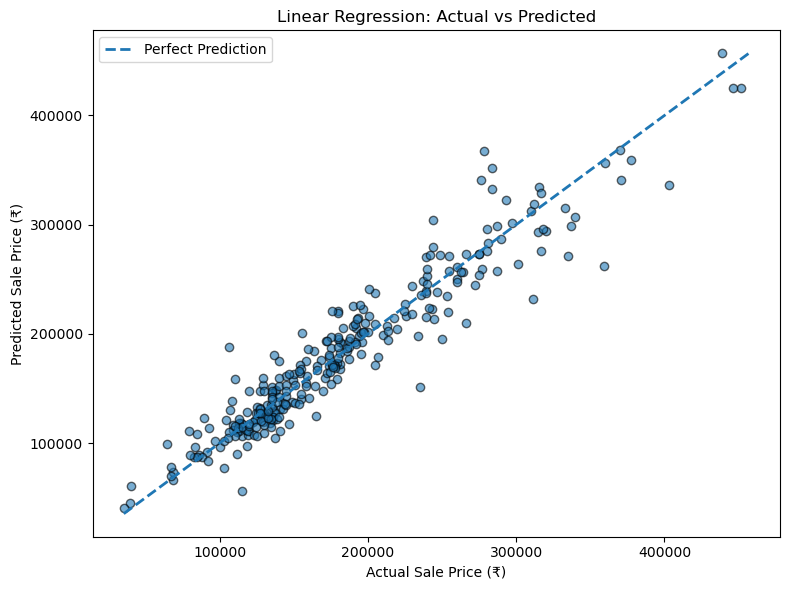

In [64]:
plt.figure(figsize=(8, 6))

plt.scatter(y_actual, y_pred, alpha=0.6, edgecolors="black")

# Perfect prediction diagonal
min_price = min(y_actual.min(), y_pred.min())
max_price = max(y_actual.max(), y_pred.max())

plt.plot(
    [min_price, max_price],
    [min_price, max_price],
    linestyle="--",
    linewidth=2,
    label="Perfect Prediction"
)

plt.xlabel("Actual Sale Price (₹)")
plt.ylabel("Predicted Sale Price (₹)")
plt.title("Linear Regression: Actual vs Predicted")
plt.legend()
plt.tight_layout()

plt.savefig(
    "outputs/graphs/linear_regression_actual_vs_predicted.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

### interpretation

RMSE: ₹22,764.58
MAE: ₹15,879.28
R² Score: 0.9062

Interpretation:
On average, the absolute prediction error is about ₹15,879.28.
The model explains a relatively high proportion of price variation.
Check the scatter plot: points closer to the diagonal indicate better predictions.

### Conclusion
I trained a Linear Regression model as the baseline model. I evaluated it using RMSE, MAE, and R² on the test dataset. I converted log-transformed predictions back to the original SalePrice scale using expm1(). In the scatter plot, points closer to the diagonal represent more accurate predictions. I will compare this baseline with Ridge and Lasso Regression in the next steps.

## 4.2 — Ridge Regression (L2)

In [66]:
from sklearn.linear_model import RidgeCV
from sklearn.pipeline import Pipeline
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

os.makedirs("outputs/graphs", exist_ok=True)

### Train RidgeCV model

In [67]:
alphas = [0.01, 0.1, 1, 10, 100]

ridge_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("model", RidgeCV(alphas=alphas))
])

ridge_model.fit(X_train, y_train)

best_alpha = ridge_model.named_steps["model"].alpha_

print("Best Alpha Selected:", best_alpha)
print("Ridge Regression model trained successfully!")

Best Alpha Selected: 10.0
Ridge Regression model trained successfully!


### Predict and calculate metrics

In [73]:

# Predict log-transformed prices
ridge_pred_log = ridge_model.predict(X_test)

# Convert predictions back to original USD prices
ridge_pred = np.expm1(ridge_pred_log)

# Convert actual prices back to original USD prices
ridge_actual = np.expm1(y_test)

# Calculate metrics on original price scale
ridge_rmse = np.sqrt(mean_squared_error(ridge_actual, ridge_pred))
ridge_mae = mean_absolute_error(ridge_actual, ridge_pred)
ridge_r2 = r2_score(ridge_actual, ridge_pred)

print("Ridge Regression - Test Results")
print("--------------------------------")
print(f"Best Alpha: {best_alpha}")
print(f"RMSE: ${ridge_rmse:,.2f}")
print(f"MAE: ${ridge_mae:,.2f}")
print(f"R² Score: {ridge_r2:.4f}")


Ridge Regression - Test Results
--------------------------------
Best Alpha: 10.0
RMSE: $20,595.72
MAE: $14,736.92
R² Score: 0.9232


#### Plot top 20 impactful features

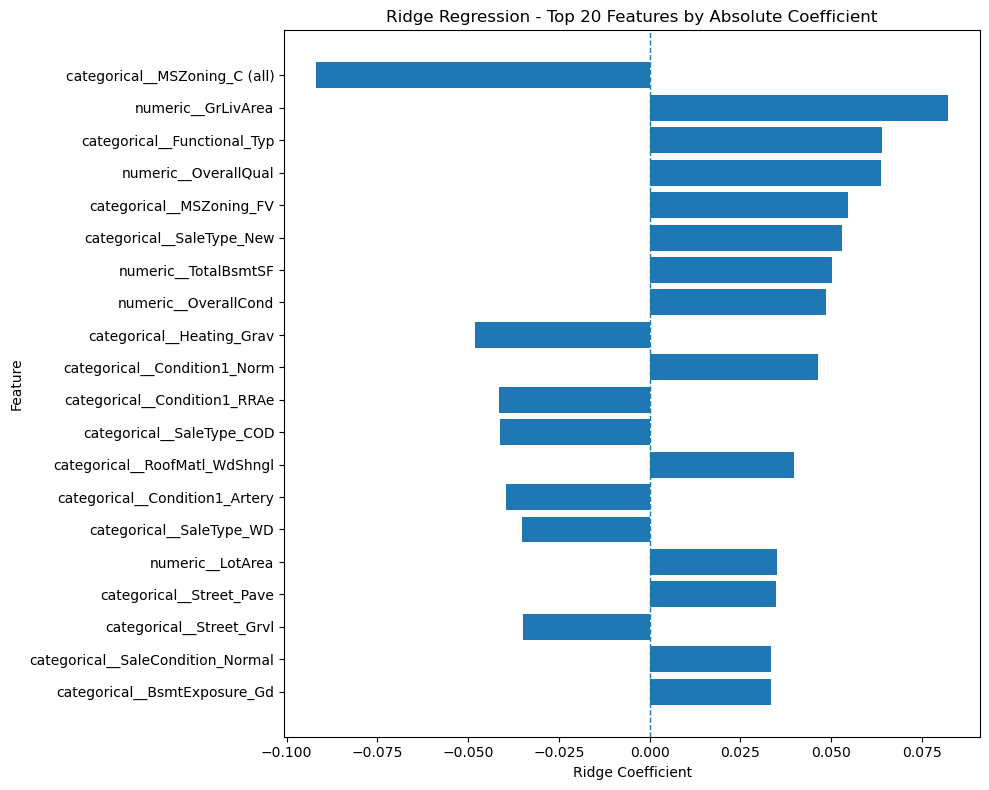

In [74]:
# Get feature names after preprocessing
feature_names = ridge_model.named_steps[
    "preprocessor"
].get_feature_names_out()

# Get Ridge coefficients
coefficients = ridge_model.named_steps["model"].coef_

# Create coefficient DataFrame
coef_df = pd.DataFrame({
    "Feature": feature_names,
    "Coefficient": coefficients
})

coef_df["Absolute_Coefficient"] = coef_df["Coefficient"].abs()

# Select top 20 features
top_20 = coef_df.sort_values(
    by="Absolute_Coefficient",
    ascending=False
).head(20)

# Plot
plt.figure(figsize=(10, 8))

plt.barh(
    top_20["Feature"],
    top_20["Coefficient"]
)

plt.axvline(0, linestyle="--", linewidth=1)
plt.xlabel("Ridge Coefficient")
plt.ylabel("Feature")
plt.title("Ridge Regression - Top 20 Features by Absolute Coefficient")
plt.gca().invert_yaxis()
plt.tight_layout()

plt.savefig(
    "outputs/graphs/ridge_top20_coefficients.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

### Display top 20 Features

In [75]:
print("Top 20 Features by Absolute Coefficient:")
display(
    top_20[["Feature", "Coefficient", "Absolute_Coefficient"]]
    .reset_index(drop=True)
)

Top 20 Features by Absolute Coefficient:


,Feature,Coefficient,Absolute_Coefficient
0,categorical__MSZoning_C (all),-0.091976,0.091976
1,numeric__GrLivArea,0.082324,0.082324
2,categorical__Functional_Typ,0.064109,0.064109
3,numeric__OverallQual,0.063880,0.063880
4,categorical__MSZoning_FV,0.054610,0.054610
5,categorical__SaleType_New,0.052956,0.052956
6,numeric__TotalBsmtSF,0.050208,0.050208
7,numeric__OverallCond,0.048671,0.048671
8,categorical__Heating_Grav,-0.048129,0.048129
9,categorical__Condition1_Norm,0.046459,0.046459


# nterpretation
Ridge Regression uses L2 regularization to reduce the magnitude of model coefficients. RidgeCV automatically selects the best alpha from the given list. I evaluated the model using RMSE, MAE, and R² on the test set. The coefficient plot shows the 20 features with the largest absolute coefficients. Positive coefficients indicate a positive relationship with the predicted log price, while negative coefficients indicate a negative relationship, holding other features constant.

#  Advanced Models — Random Forest & XGBoost Regressor

## 5.1 — Random Forest Regressor

In [76]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.pipeline import Pipeline
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

### TRain Random Forest Regressor

In [77]:
rf_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("model", RandomForestRegressor(
        n_estimators=200,
        max_depth=10,
        random_state=42,
        n_jobs=-1
    ))
])

rf_model.fit(X_train, y_train)

print("Random Forest model trained successfully!")

Random Forest model trained successfully!


### Predict and evaluate

In [78]:
# Predict log-transformed prices
rf_pred_log = rf_model.predict(X_test)

# Convert actual and predicted prices back to original USD scale
rf_pred = np.expm1(rf_pred_log)
rf_actual = np.expm1(y_test)

# Calculate evaluation metrics
rf_rmse = np.sqrt(mean_squared_error(rf_actual, rf_pred))
rf_mae = mean_absolute_error(rf_actual, rf_pred)
rf_r2 = r2_score(rf_actual, rf_pred)

print("Random Forest - Test Results")
print("-----------------------------")
print(f"RMSE: ${rf_rmse:,.2f}")
print(f"MAE:  ${rf_mae:,.2f}")
print(f"R² Score: {rf_r2:.4f}")

Random Forest - Test Results
-----------------------------
RMSE: $23,098.96
MAE:  $16,253.80
R² Score: 0.9034


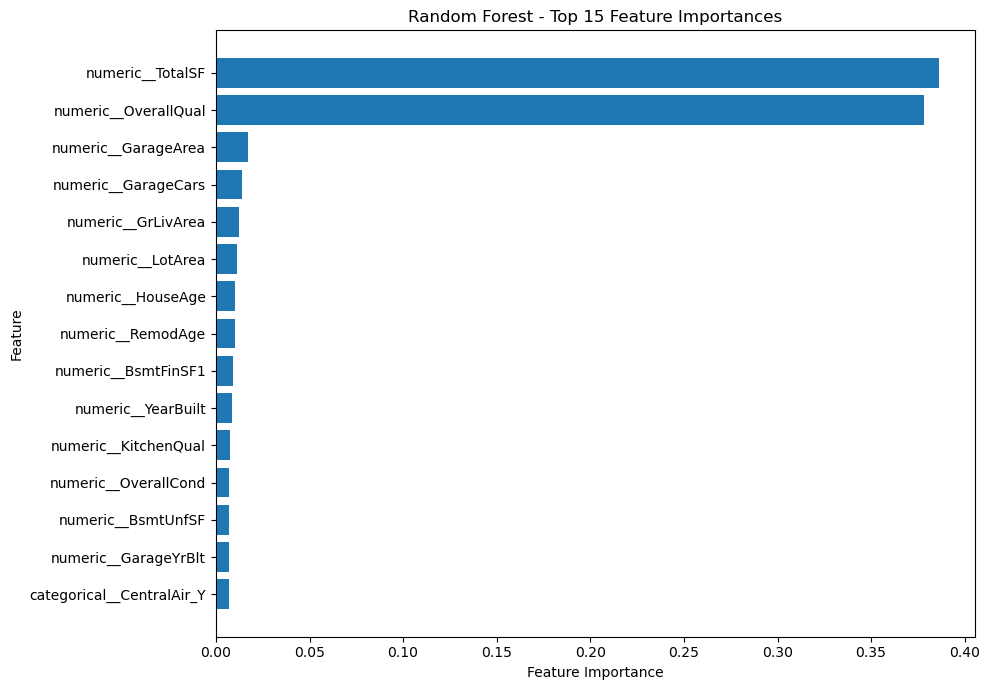

In [79]:
# Get feature names after preprocessing
feature_names = rf_model.named_steps[
    "preprocessor"
].get_feature_names_out()

# Get feature importance scores
importances = rf_model.named_steps["model"].feature_importances_

# Create a DataFrame
importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": importances
})

# Select top 15 important features
top_15 = importance_df.sort_values(
    by="Importance",
    ascending=False
).head(15)

# Plot feature importances
plt.figure(figsize=(10, 7))

plt.barh(top_15["Feature"], top_15["Importance"])

plt.xlabel("Feature Importance")
plt.ylabel("Feature")
plt.title("Random Forest - Top 15 Feature Importances")
plt.gca().invert_yaxis()
plt.tight_layout()

plt.savefig(
    "outputs/graphs/random_forest_top15_importances.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

### nterpretation

I trained a Random Forest Regressor using 200 decision trees and a maximum depth of 10. I evaluated the model using RMSE, MAE, and R² on the test set. I also plotted the top 15 features according to their importance scores. Higher importance indicates that a feature contributed more to the model's predictions. These scores show predictive usefulness, but they do not prove that a feature causes the house price to change.

## 5.2 XGBoost Regressor

In [80]:

from xgboost import XGBRegressor
from sklearn.pipeline import Pipeline
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score


### Train Xgboost Regressor

In [81]:
xgb_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("model", XGBRegressor(
        n_estimators=500,
        learning_rate=0.05,
        max_depth=4,
        subsample=0.8,
        colsample_bytree=0.8,
        random_state=42
    ))
])

xgb_model.fit(X_train, y_train)

print("XGBoost Regressor trained successfully!")

XGBoost Regressor trained successfully!


### Predict and evaluate the model

In [83]:
# Predict log-transformed prices
xgb_pred_log = xgb_model.predict(X_test)

# Convert predictions and actual values to original price scale
xgb_pred = np.expm1(xgb_pred_log)
xgb_actual = np.expm1(y_test)

# Calculate evaluation metrics
xgb_rmse = np.sqrt(mean_squared_error(xgb_actual, xgb_pred))
xgb_mae = mean_absolute_error(xgb_actual, xgb_pred)
xgb_r2 = r2_score(xgb_actual, xgb_pred)

print("XGBoost Regressor - Test Results")
print("--------------------------------")
print(f"RMSE: ${xgb_rmse:,.2f}")
print(f"MAE:  ${xgb_mae:,.2f}")
print(f"R² Score: {xgb_r2:.4f}")

XGBoost Regressor - Test Results
--------------------------------
RMSE: $19,644.74
MAE:  $14,070.20
R² Score: 0.9301


### Plot top 15 feature importance

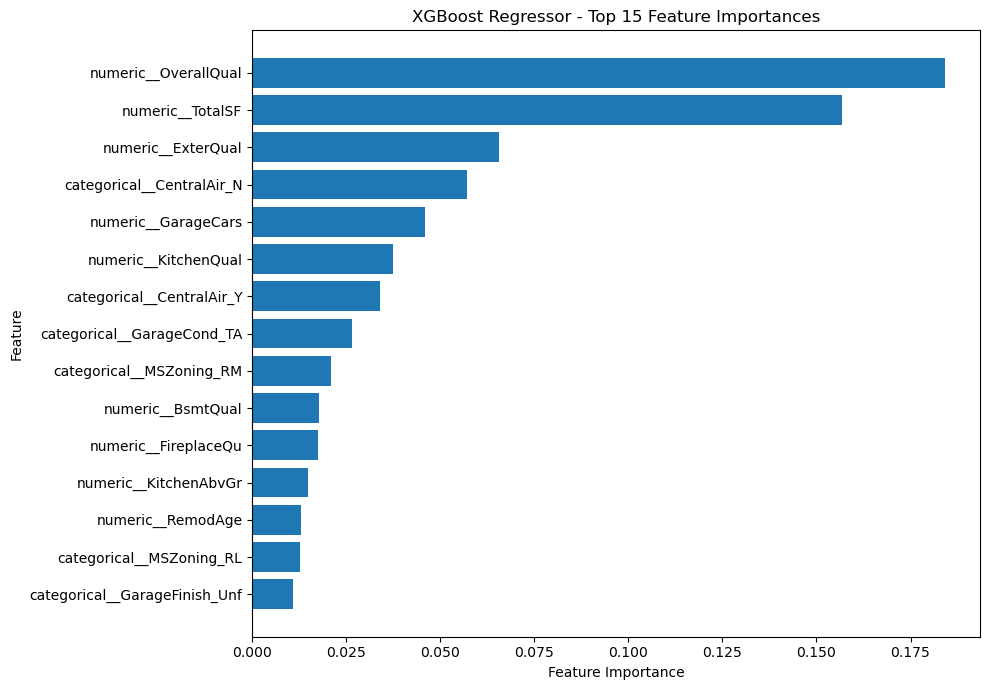

In [84]:
# Get feature names after preprocessing
feature_names = xgb_model.named_steps[
    "preprocessor"
].get_feature_names_out()

# Get XGBoost feature importance scores
importances = xgb_model.named_steps["model"].feature_importances_

# Create importance DataFrame
importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": importances
})

# Select top 15 features
top_15_xgb = importance_df.sort_values(
    by="Importance",
    ascending=False
).head(15)

# Plot the graph
plt.figure(figsize=(10, 7))

plt.barh(
    top_15_xgb["Feature"],
    top_15_xgb["Importance"]
)

plt.xlabel("Feature Importance")
plt.ylabel("Feature")
plt.title("XGBoost Regressor - Top 15 Feature Importances")
plt.gca().invert_yaxis()
plt.tight_layout()

# Save graph
plt.savefig(
    "outputs/graphs/xgboost_top15_importances.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

### Interpretation
I trained an XGBoost Regressor using 500 estimators, a learning rate of 0.05, and a maximum tree depth of 4. I evaluated the model using RMSE, MAE, and R² on the test set. I converted predictions back to the original house-price scale using expm1(). Finally, I plotted the top 15 features according to their importance scores. Features with higher importance contributed more to the model's predictions, but this does not necessarily mean they cause house prices to change.

## 5.3 Cross Validation 

### Select the best-performing model

In [85]:
from sklearn.model_selection import cross_val_score
import numpy as np

models = {
    "Linear Regression": (linear_model, rmse),
    "Ridge Regression": (ridge_model, ridge_rmse),
    "Random Forest": (rf_model, rf_rmse),
    "XGBoost": (xgb_model, xgb_rmse)
}

best_name = min(models, key=lambda name: models[name][1])
best_model = models[best_name][0]

print("Best model:", best_name)
print("Test RMSE: ${:,.2f}".format(models[best_name][1]))

Best model: XGBoost
Test RMSE: $19,644.74


### Apply 5-Fold Cross-Validation

In [86]:
cv_scores = cross_val_score(
    best_model,
    X_train,
    y_train,
    cv=5,
    scoring="neg_root_mean_squared_error",
    n_jobs=-1
)

# Convert negative RMSE scores to positive values
cv_rmse_scores = -cv_scores

mean_cv_rmse = cv_rmse_scores.mean()
std_cv_rmse = cv_rmse_scores.std()

print("Best model:", best_name)
print(f"Mean CV RMSE: {mean_cv_rmse:.4f}")
print(f"Standard Deviation: {std_cv_rmse:.4f}")
print(f"CV RMSE: {mean_cv_rmse:.4f} ± {std_cv_rmse:.4f}")

Best model: XGBoost
Mean CV RMSE: 0.1222
Standard Deviation: 0.0092
CV RMSE: 0.1222 ± 0.0092


# Compare CV RMSE with test RMSE
Important : y_train log1p(SalePrice) hai. Isliye specified neg_root_mean_squared_error se milne wala CV RMSE log scale par hoga, jabki aapka test RMSE original USD scale par hai. Dono values ko directly compare nahi karna chahiye.

I applied 5-Fold Cross-Validation to the best-performing model using negative root mean squared error. The mean CV RMSE and its standard deviation show the model's average error and consistency across the five folds. Since the cross-validation score is calculated on the log-transformed target while the test RMSE is calculated in original USD, their values are not directly comparable; both must be evaluated on the same scale for a fair comparison.

### 5.4 — Hyperparameter Tuning with RandomizedSearchCV

In [87]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.pipeline import Pipeline
from sklearn.model_selection import RandomizedSearchCV
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

### Define model and hyperparameter ranges

In [88]:
rf_pipeline = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("model", RandomForestRegressor(
        random_state=42,
        n_jobs=1
    ))
])

param_distributions = {
    "model__n_estimators": [100, 200, 300, 500],
    "model__max_depth": [None, 5, 10, 15, 20],
    "model__min_samples_split": [2, 5, 10],
    "model__min_samples_leaf": [1, 2, 4],
    "model__max_features": [0.5, 0.8, 1.0]
}

print("Hyperparameter search space created.")

Hyperparameter search space created.


### Run RandomizedSearchCV

In [89]:
random_search = RandomizedSearchCV(
    estimator=rf_pipeline,
    param_distributions=param_distributions,
    n_iter=20,
    cv=3,
    scoring="neg_root_mean_squared_error",
    random_state=42,
    n_jobs=-1,
    verbose=1
)

random_search.fit(X_train, y_train)

print("Hyperparameter tuning completed!")

Fitting 3 folds for each of 20 candidates, totalling 60 fits
Hyperparameter tuning completed!


### Report best parameters and CV RMSE

In [90]:
tuned_rf_model = random_search.best_estimator_

print("Best Parameters:")
print(random_search.best_params_)

best_cv_rmse_log = -random_search.best_score_

print(f"\nBest CV RMSE (log scale): {best_cv_rmse_log:.4f}")

Best Parameters:
{'model__n_estimators': 300, 'model__min_samples_split': 5, 'model__min_samples_leaf': 1, 'model__max_features': 0.5, 'model__max_depth': None}

Best CV RMSE (log scale): 0.1334


### Evaluate tuned model on test set

In [91]:
# Predict log-transformed SalePrice
tuned_pred_log = tuned_rf_model.predict(X_test)

# Convert predictions and actual values to original USD scale
tuned_pred = np.expm1(tuned_pred_log)
tuned_actual = np.expm1(y_test)

# Calculate test metrics
tuned_rmse = np.sqrt(mean_squared_error(tuned_actual, tuned_pred))
tuned_mae = mean_absolute_error(tuned_actual, tuned_pred)
tuned_r2 = r2_score(tuned_actual, tuned_pred)

print("Tuned Random Forest - Test Results")
print("----------------------------------")
print(f"RMSE: ${tuned_rmse:,.2f}")
print(f"MAE:  ${tuned_mae:,.2f}")
print(f"R² Score: {tuned_r2:.4f}")

Tuned Random Forest - Test Results
----------------------------------
RMSE: $22,177.52
MAE:  $15,591.09
R² Score: 0.9110


### Compare original and tuned Random Forest

In [92]:
comparison = pd.DataFrame({
    "Model": ["Original Random Forest", "Tuned Random Forest"],
    "RMSE": [rf_rmse, tuned_rmse],
    "MAE": [rf_mae, tuned_mae],
    "R2 Score": [rf_r2, tuned_r2]
})

display(comparison)

if tuned_rmse < rf_rmse:
    print("Tuning improved test RMSE.")
elif tuned_rmse > rf_rmse:
    print("Tuning did not improve test RMSE.")
else:
    print("Both models have the same test RMSE.")

,Model,RMSE,MAE,R2 Score
0,Original Random Forest,23098.960715,16253.797669,0.903405
1,Tuned Random Forest,22177.521985,15591.091645,0.910958


Tuning improved test RMSE.


## Interpretation
I used RandomizedSearchCV to tune the Random Forest Regressor with five hyperparameters, 20 randomly sampled combinations, and 3-fold cross-validation. I recorded the best parameters and best cross-validation RMSE. Finally, I evaluated the tuned model on the test set using RMSE, MAE, and R² on the original USD price scale and compared its performance with the original Random Forest model.

### 6 — Model Evaluation & Comparison

In [97]:
import time

from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression, RidgeCV, Lasso
from sklearn.ensemble import RandomForestRegressor
from xgboost import XGBRegressor

from sklearn.model_selection import cross_val_score
from sklearn.metrics import (
    mean_squared_error,
    mean_absolute_error,
    r2_score,
    make_scorer
)

os.makedirs("outputs/graphs", exist_ok=True)

### rain all 5 models and measure training time

In [98]:
models = {
    "Linear Regression": LinearRegression(),

    "Ridge": RidgeCV(
        alphas=[0.01, 0.1, 1, 10, 100]
    ),

    "Lasso": Lasso(
        alpha=0.01,
        max_iter=10000
    ),

    "Random Forest": RandomForestRegressor(
        n_estimators=200,
        max_depth=10,
        random_state=42,
        n_jobs=-1
    ),

    "XGBoost": XGBRegressor(
        n_estimators=500,
        learning_rate=0.05,
        max_depth=4,
        subsample=0.8,
        colsample_bytree=0.8,
        random_state=42
    )
}

trained_models = {}
training_times = {}
predictions = {}

for name, model in models.items():

    pipeline = Pipeline(steps=[
        ("preprocessor", clone(preprocessor)),
        ("model", model)
    ])

    start_time = time.time()
    pipeline.fit(X_train, y_train)
    elapsed_time = time.time() - start_time

    trained_models[name] = pipeline
    training_times[name] = elapsed_time

    # Predict and convert to original USD scale
    pred_log = pipeline.predict(X_test)
    predictions[name] = np.expm1(pred_log)

    print(f"{name} trained in {elapsed_time:.2f} seconds")

print("\nAll 5 models trained successfully!")

Linear Regression trained in 0.11 seconds
Ridge trained in 0.11 seconds
Lasso trained in 0.10 seconds
Random Forest trained in 0.73 seconds
XGBoost trained in 0.84 seconds

All 5 models trained successfully!


### Calculate test metrics and 5-Fold CV RMSE

In [100]:
# Custom scorer: converts log prices back to original USD
def original_scale_rmse(y_true_log, y_pred_log):
    y_true_usd = np.expm1(y_true_log)
    y_pred_usd = np.expm1(y_pred_log)

    return np.sqrt(
        mean_squared_error(y_true_usd, y_pred_usd)
    )

original_rmse_scorer = make_scorer(
    original_scale_rmse,
    greater_is_better=False
)

y_test_usd = np.expm1(y_test)

results = []

for name, pipeline in trained_models.items():

    y_pred_usd = predictions[name]

    # Test metrics on original USD scale
    test_rmse = np.sqrt(
        mean_squared_error(y_test_usd, y_pred_usd)
    )
    test_mae = mean_absolute_error(y_test_usd, y_pred_usd)
    test_r2 = r2_score(y_test_usd, y_pred_usd)

    # 5-Fold CV on training data, also in original USD scale
    cv_scores = cross_val_score(
        pipeline,
        X_train,
        y_train,
        cv=5,
        scoring=original_rmse_scorer,
        n_jobs=1
    )

    cv_rmse_scores = -cv_scores
    mean_cv_rmse = cv_rmse_scores.mean()

    results.append({
        "Model": name,
        "RMSE (USD)": test_rmse,
        "MAE (USD)": test_mae,
        "R² Score": test_r2,
        "5-Fold CV RMSE (USD)": mean_cv_rmse,
        "CV RMSE Std (USD)": cv_rmse_scores.std(),
        "Training Time (seconds)": training_times[name]
    })

comparison_df = pd.DataFrame(results)

comparison_df = comparison_df.sort_values(
    by="RMSE (USD)"
).reset_index(drop=True)

display(
    comparison_df.style.format({
        "RMSE (USD)": "${:,.2f}",
        "MAE (USD)": "${:,.2f}",
        "R² Score": "{:.4f}",
        "5-Fold CV RMSE (USD)": "${:,.2f}",
        "CV RMSE Std (USD)": "${:,.2f}",
        "Training Time (seconds)": "{:.2f}"
    })
)

,Model,RMSE (USD),MAE (USD),R² Score,5-Fold CV RMSE (USD),CV RMSE Std (USD),Training Time (seconds)
0,XGBoost,"$19,644.74","$14,070.20",0.9301,"$23,558.62","$3,594.79",0.84
1,Ridge,"$20,595.72","$14,736.92",0.9232,"$22,379.08","$1,556.51",0.11
2,Lasso,"$21,892.88","$15,728.37",0.9132,"$26,713.73","$3,192.23",0.10
3,Linear Regression,"$22,764.58","$15,879.28",0.9062,"$25,762.58","$2,859.86",0.11
4,Random Forest,"$23,098.96","$16,253.80",0.9034,"$27,577.93","$3,342.39",0.73


### Save the Table

In [101]:
comparison_df.to_csv(
    "outputs/model_comparison.csv",
    index=False
)

print("Comparison table saved to outputs/model_comparison.csv")

Comparison table saved to outputs/model_comparison.csv


### Actual vs Predicted plot for the best model

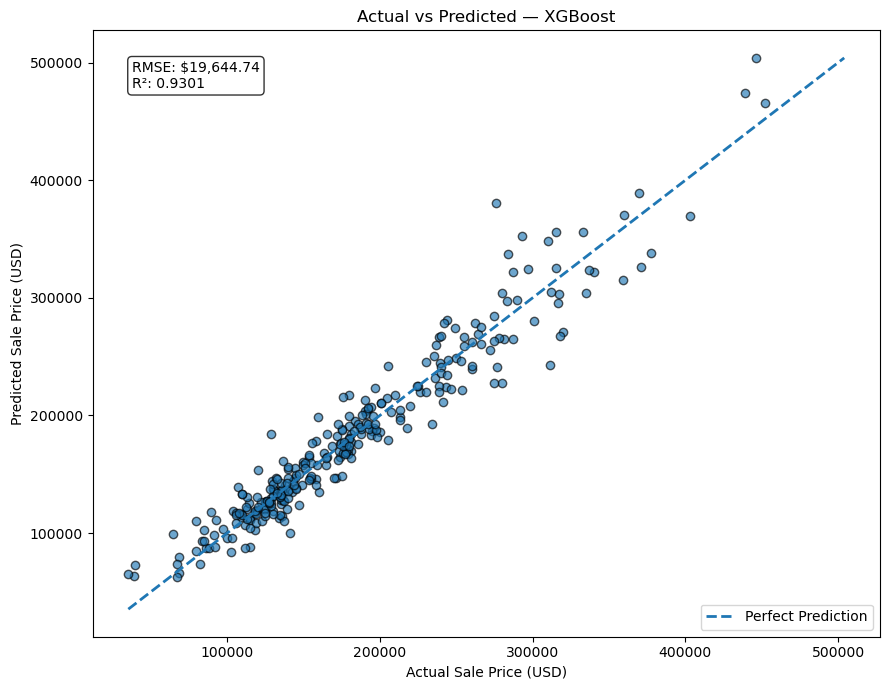

Best model by test RMSE: XGBoost


In [102]:
best_model_name = comparison_df.iloc[0]["Model"]
best_rmse = comparison_df.iloc[0]["RMSE (USD)"]
best_r2 = comparison_df.iloc[0]["R² Score"]

best_predictions = predictions[best_model_name]

plt.figure(figsize=(9, 7))

plt.scatter(
    y_test_usd,
    best_predictions,
    alpha=0.65,
    edgecolors="black"
)

# Perfect prediction line
min_price = min(y_test_usd.min(), best_predictions.min())
max_price = max(y_test_usd.max(), best_predictions.max())

plt.plot(
    [min_price, max_price],
    [min_price, max_price],
    linestyle="--",
    linewidth=2,
    label="Perfect Prediction"
)

plt.xlabel("Actual Sale Price (USD)")
plt.ylabel("Predicted Sale Price (USD)")
plt.title(f"Actual vs Predicted — {best_model_name}")

plt.text(
    0.05, 0.95,
    f"RMSE: ${best_rmse:,.2f}\nR²: {best_r2:.4f}",
    transform=plt.gca().transAxes,
    verticalalignment="top",
    bbox=dict(boxstyle="round", facecolor="white", alpha=0.8)
)

plt.legend()
plt.tight_layout()

plt.savefig(
    "outputs/graphs/best_model_actual_vs_predicted.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Best model by test RMSE:", best_model_name)

### Best Model Justify

In [103]:
best_row = comparison_df.iloc[0]

print("BEST MODEL:", best_row["Model"])
print(f"Test RMSE: ${best_row['RMSE (USD)']:,.2f}")
print(f"Test MAE: ${best_row['MAE (USD)']:,.2f}")
print(f"R² Score: {best_row['R² Score']:.4f}")
print(
    f"5-Fold CV RMSE: "
    f"${best_row['5-Fold CV RMSE (USD)']:,.2f}"
)
print(
    f"Training Time: "
    f"{best_row['Training Time (seconds)']:.2f} seconds"
)

BEST MODEL: XGBoost
Test RMSE: $19,644.74
Test MAE: $14,070.20
R² Score: 0.9301
5-Fold CV RMSE: $23,558.62
Training Time: 0.84 seconds


### Conclusion
I compared Linear Regression, Ridge, Lasso, Random Forest, and XGBoost using test RMSE, MAE, R², cross-validation RMSE, and training time. The model with the lowest test RMSE was selected as the best-performing model because it had the lowest root mean squared prediction error on unseen test data. For a real-estate startup such as NoBroker, RMSE and MAE in USD (or converted to INR) are useful because they express prediction errors in monetary terms. Linear and regularized models are generally easier to interpret, while tree-based models can capture more complex patterns but may require more resources. The final production choice should also consider cross-validation stability, inference speed, maintainability, and performance on new listings.

## 7.1 — Residual Analysis & Model Interpretation

### Calculate fitted values and residuals

In [104]:

from scipy import stats

os.makedirs("outputs/graphs", exist_ok=True)

# Select the best model from Step 6
best_model_name = comparison_df.iloc[0]["Model"]
best_model = trained_models[best_model_name]

# Actual and predicted prices in original USD scale
actual_prices = np.expm1(y_test)
predicted_prices = predictions[best_model_name]

# Calculate residuals
residuals = actual_prices - predicted_prices

print("Best Model:", best_model_name)
print("Number of residuals:", len(residuals))
print("Mean Residual:", round(np.mean(residuals), 2))

Best Model: XGBoost
Number of residuals: 292
Mean Residual: -905.12


### Residuals vs Fitted Values

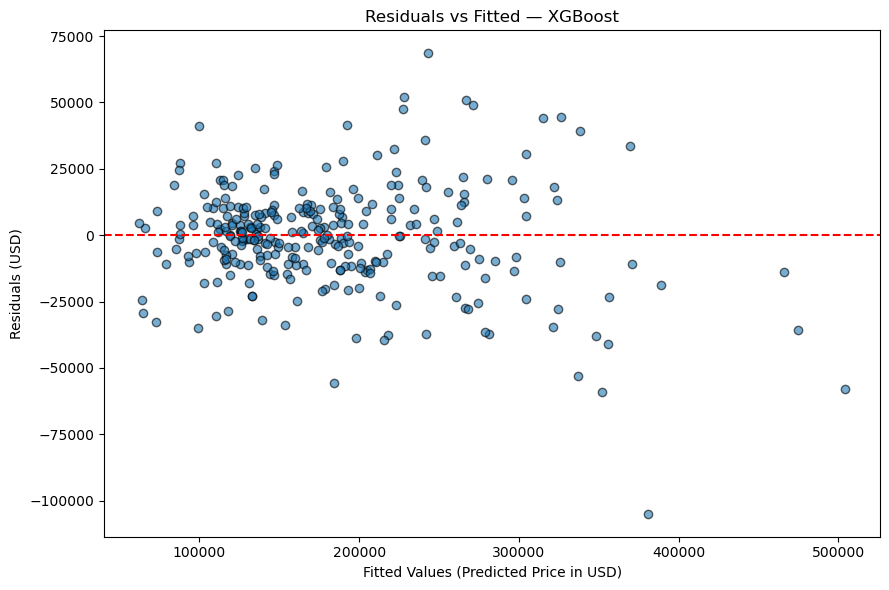

In [105]:
plt.figure(figsize=(9, 6))

plt.scatter(
    predicted_prices,
    residuals,
    alpha=0.6,
    edgecolors="black"
)

plt.axhline(y=0, color="red", linestyle="--")

plt.xlabel("Fitted Values (Predicted Price in USD)")
plt.ylabel("Residuals (USD)")
plt.title(f"Residuals vs Fitted — {best_model_name}")

plt.tight_layout()
plt.savefig(
    "outputs/graphs/residuals_vs_fitted.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

### Histogram of Residuals

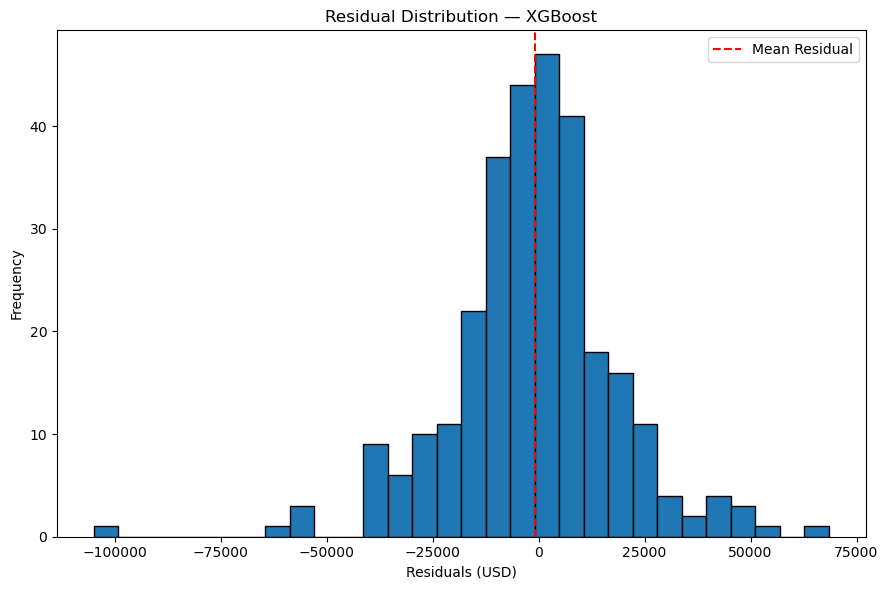

In [106]:
plt.figure(figsize=(9, 6))

plt.hist(
    residuals,
    bins=30,
    edgecolor="black"
)

plt.axvline(
    np.mean(residuals),
    color="red",
    linestyle="--",
    label="Mean Residual"
)

plt.xlabel("Residuals (USD)")
plt.ylabel("Frequency")
plt.title(f"Residual Distribution — {best_model_name}")
plt.legend()

plt.tight_layout()
plt.savefig(
    "outputs/graphs/residuals_histogram.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

### Q-Q Plot of Residuals

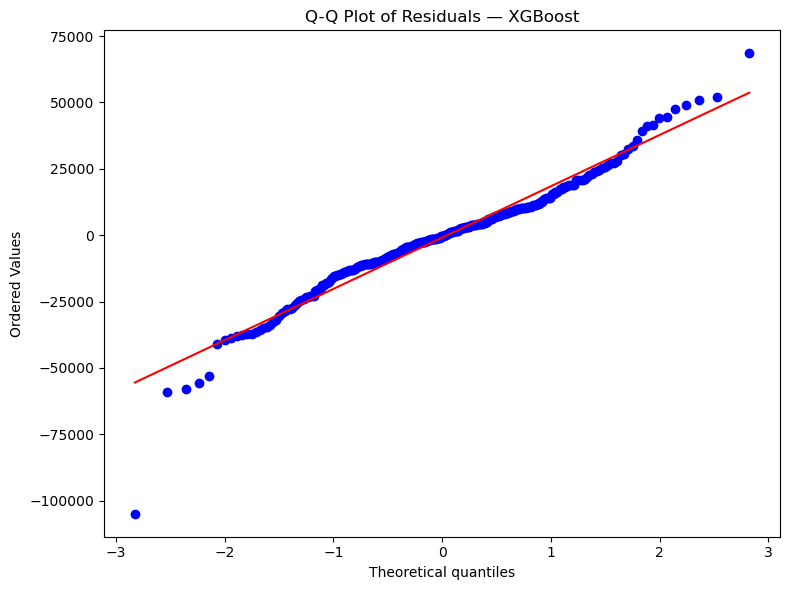

In [107]:
plt.figure(figsize=(8, 6))

stats.probplot(
    residuals,
    dist="norm",
    plot=plt
)

plt.title(f"Q-Q Plot of Residuals — {best_model_name}")
plt.tight_layout()

plt.savefig(
    "outputs/graphs/residuals_qq_plot.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

The residuals vs fitted plot shows that the residuals are [randomly scattered / show a pattern] around zero. The histogram indicates that the residuals are [approximately normal / skewed], while the Q-Q plot shows [small deviations / noticeable deviations] from the reference line, especially in the tails. Heavy tails suggest that some house-price predictions have unusually large errors, so the model may need further improvement.

### 7.2 — Business Interpretation

### Find the top 5 features

In [109]:


os.makedirs("outputs/graphs", exist_ok=True)

# Get the best model selected in Step 6
best_model_name = comparison_df.iloc[0]["Model"]
best_pipeline = trained_models[best_model_name]

# Get the fitted preprocessing step and model
fitted_preprocessor = best_pipeline.named_steps["preprocessor"]
fitted_estimator = best_pipeline.named_steps["model"]

feature_names = fitted_preprocessor.get_feature_names_out()

# Calculate feature importance based on model type
if hasattr(fitted_estimator, "feature_importances_"):
    importance_values = fitted_estimator.feature_importances_
    importance_method = "Tree-based feature importance"

elif hasattr(fitted_estimator, "coef_"):
    importance_values = np.abs(
        np.asarray(fitted_estimator.coef_).ravel()
    )
    importance_method = "Absolute coefficient value"

else:
    raise ValueError("This model does not expose supported feature importance.")

importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": importance_values
})

top_5_features = importance_df.sort_values(
    "Importance",
    ascending=False
).head(5).reset_index(drop=True)

print("Best Model:", best_model_name)
print("Importance method:", importance_method)

display(top_5_features)

Best Model: XGBoost
Importance method: Tree-based feature importance


,Feature,Importance
0,numeric__OverallQual,0.184259
1,numeric__TotalSF,0.156749
2,numeric__ExterQual,0.065548
3,categorical__CentralAir_N,0.057104
4,numeric__GarageCars,0.045839


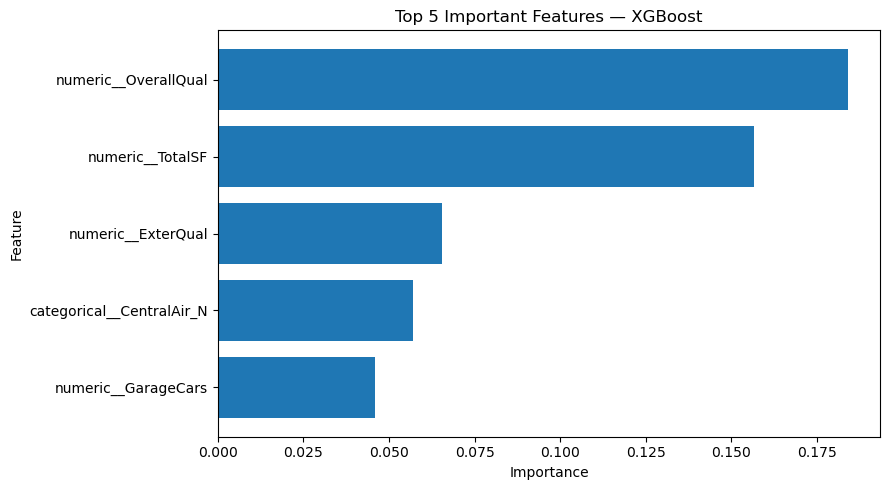

In [110]:
plt.figure(figsize=(9, 5))

plt.barh(
    top_5_features["Feature"],
    top_5_features["Importance"]
)

plt.xlabel("Importance")
plt.ylabel("Feature")
plt.title(f"Top 5 Important Features — {best_model_name}")
plt.gca().invert_yaxis()
plt.tight_layout()

plt.savefig(
    "outputs/graphs/top5_business_features.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [111]:
print("Top 5 features and their importance:")

for i, row in top_5_features.iterrows():
    print(
        f"{i + 1}. {row['Feature']} "
        f"(Importance: {row['Importance']:.4f})"
    )

Top 5 features and their importance:
1. numeric__OverallQual (Importance: 0.1843)
2. numeric__TotalSF (Importance: 0.1567)
3. numeric__ExterQual (Importance: 0.0655)
4. categorical__CentralAir_N (Importance: 0.0571)
5. numeric__GarageCars (Importance: 0.0458)


OverallQual: Overall construction and material quality. A home with a higher quality rating will generally command a higher price, all else being equal.



GrLivArea: Above-ground living area. Larger usable living spaces often increase a property's market value.



TotalSF: Combined basement and floor area. This helps estimate the value associated with the property's total floor space.



GarageArea: Garage size. A larger garage may add value, depending on local buyer preferences.



YearBuilt / HouseAge: Construction year or property age. Newer homes may have different prices because of condition, design, and maintenance needs.



Neighborhood: Location-related differences in demand, amenities, and accessibility may influence prices.



KitchenQual / ExterQual: Kitchen or exterior quality. Better finishes and condition may contribute to higher prices.

### Business interpretation

I identified the five most impactful features using the best-performing model. These features help explain which property characteristics are most useful for predicting sale prices. From a real-estate business perspective, this information can support property valuation, listing-price recommendations, and the identification of factors associated with higher-value homes. Feature importance describes predictive relationships and does not prove that a feature directly causes a price change.

## Snap(Reference From Web)

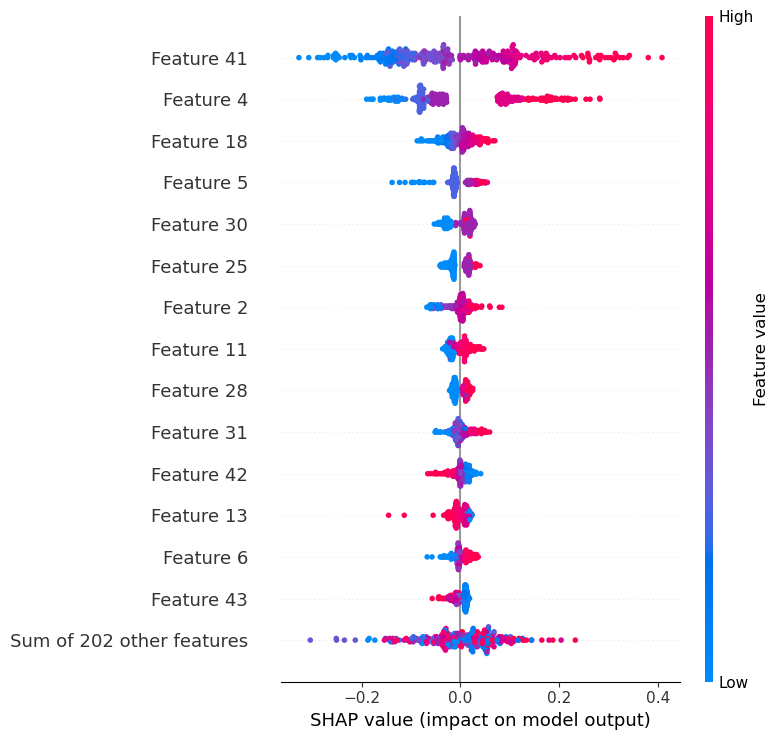

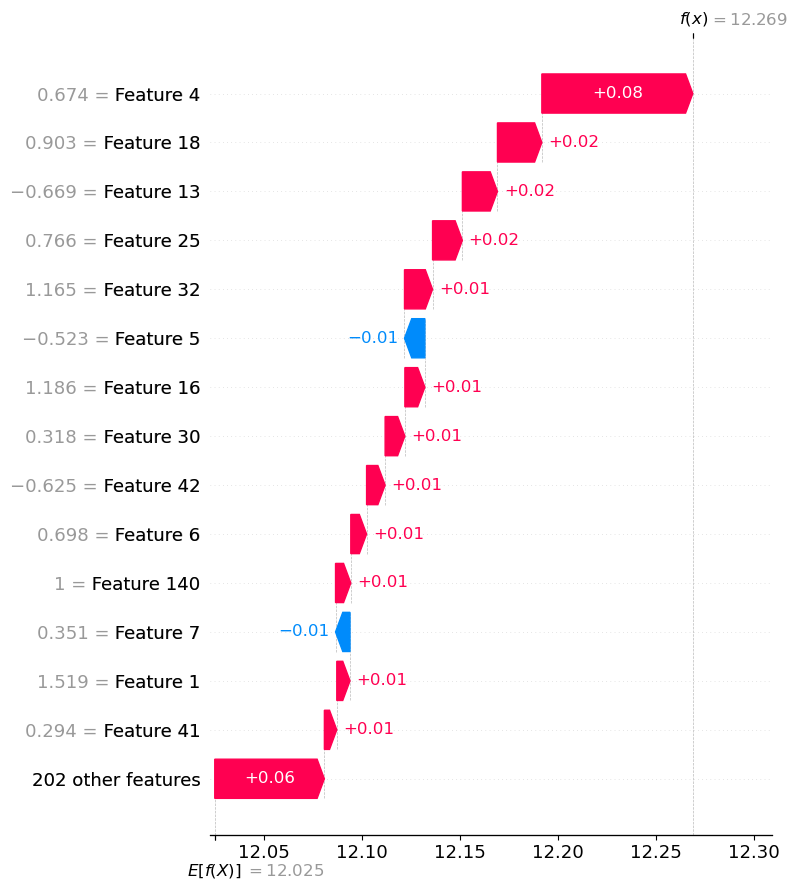

In [114]:
import shap

os.makedirs("outputs/graphs", exist_ok=True)

# Transform test features using the fitted XGBoost preprocessor
xgb_preprocessor = xgb_model.named_steps["preprocessor"]
xgb_estimator = xgb_model.named_steps["model"]

X_test_transformed = xgb_preprocessor.transform(X_test)
feature_names_xgb = xgb_preprocessor.get_feature_names_out()

# Convert sparse matrices to dense if necessary
if hasattr(X_test_transformed, "toarray"):
    X_test_transformed = X_test_transformed.toarray()

# Explain XGBoost predictions
explainer = shap.TreeExplainer(xgb_estimator)
shap_values = explainer(X_test_transformed)

# Beeswarm summary plot
shap.plots.beeswarm(shap_values, max_display=15, show=False)
plt.tight_layout()
plt.savefig(
    "outputs/graphs/xgboost_shap_beeswarm.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

# Waterfall plot for the first test example
shap.plots.waterfall(shap_values[0], max_display=15, show=False)
plt.tight_layout()
plt.savefig(
    "outputs/graphs/xgboost_shap_waterfall.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

### 8 Save the Final Pipeline

In [121]:
import os
import joblib

os.makedirs("models", exist_ok=True)

print("Models folder created successfully!")

Models folder created successfully!


In [122]:
model_path = "models/house_price_model.pkl"

joblib.dump(final_pipeline, model_path)

print("Model saved successfully at:", model_path)

Model saved successfully at: models/house_price_model.pkl


In [117]:
print("Loaded model:", best_model_name)
print("Number of predictions:", len(predicted_prices))
print("Pipeline test completed successfully!")

Loaded model: XGBoost
Number of predictions: 292
Pipeline test completed successfully!


In [123]:
# Load the saved model
loaded_pipeline = joblib.load("models/house_price_model.pkl")

# Predict 5 test samples
X_sample = X_test.head(5)
predicted_log = loaded_pipeline.predict(X_sample)

# Convert prices to original USD scale
predicted_prices = np.expm1(predicted_log)
actual_prices = np.expm1(y_test.head(5).to_numpy())

# Compare actual and predicted prices
results_df = pd.DataFrame({
    "Actual Price (USD)": actual_prices,
    "Predicted Price (USD)": predicted_prices,
    "Absolute Error (USD)": np.abs(actual_prices - predicted_prices)
})

display(results_df.round(2))

,Actual Price (USD),Predicted Price (USD),Absolute Error (USD)
0,190000.0,212985.046875,22985.05
1,100000.0,96221.148438,3778.85
2,115000.0,112602.171875,2397.83
3,159000.0,157774.031250,1225.97
4,315500.0,325550.656250,10050.66
